In [ ]:

!pip install -q pandas numpy scikit-learn matplotlib seaborn plotly openpyxl streamlit langgraph langchain


In [ ]:

import os

folders = [
    "AutoPrep-AI/agents",
    "AutoPrep-AI/core",
    "AutoPrep-AI/preprocessing",
    "AutoPrep-AI/utils",
    "AutoPrep-AI/data",
    "AutoPrep-AI/reports",
    "AutoPrep-AI/tests"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("AutoPrep AI folders created successfully!")


AutoPrep AI folders created successfully!


In [ ]:

import pandas as pd
import numpy as np
import sklearn
import streamlit as st
import langgraph

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Streamlit:", st.__version__)
print("LangGraph: Installed")

print("\nAutoPrep AI environment is ready!")


Pandas: 2.2.3
NumPy: 2.4.6
Scikit-learn: 1.6.1
Streamlit: 1.67.0
LangGraph: Installed

AutoPrep AI environment is ready!


In [ ]:

import os

PROJECT = "/content/AutoPrep-AI"

folders = [
    "agents",
    "core",
    "preprocessing",
    "utils",
    "data",
    "reports",
    "tests"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT, folder), exist_ok=True)

# Create Python package initialization files
for folder in ["agents", "core", "preprocessing", "utils"]:
    init_file = os.path.join(PROJECT, folder, "__init__.py")
    open(init_file, "w").close()

print("AutoPrep AI project structure created!")

for root, dirs, files in os.walk(PROJECT):
    level = root.replace(PROJECT, "").count(os.sep)
    print("  " * level + os.path.basename(root) + "/")


AutoPrep AI project structure created!
AutoPrep-AI/
  preprocessing/
  utils/
  agents/
  data/
  tests/
  core/
  reports/


In [ ]:

from google.colab import files
import os
import shutil

uploaded = files.upload()

for filename in uploaded.keys():
    if filename.lower().endswith(".csv"):
        destination = os.path.join(
            PROJECT, "data", "employee_attrition.csv"
        )
        shutil.move(filename, destination)
        print("Dataset saved:", destination)
    else:
        print("Please upload a CSV file:", filename)


Saving archive.zip to archive.zip
Please upload a CSV file: archive.zip


In [ ]:

import pandas as pd
import os

DATA_PATH = os.path.join(
    PROJECT, "data", "employee_attrition.csv"
)

if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH)

    print("Dataset loaded successfully!")
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])

    display(df.head())

else:
    print("Dataset not found. Please upload the CSV.")


Dataset not found. Please upload the CSV.


In [ ]:

from google.colab import files
import os
import shutil

PROJECT = "/content/AutoPrep-AI"
DATA_DIR = os.path.join(PROJECT, "data")

os.makedirs(DATA_DIR, exist_ok=True)

uploaded = files.upload()

for filename in uploaded.keys():
    if filename.lower().endswith(".csv"):
        destination = os.path.join(
            DATA_DIR, "employee_attrition.csv"
        )

        shutil.copy(filename, destination)

        print("Upload successful!")
        print("Saved location:", destination)
    else:
        print("Please select a CSV file.")


Saving Employee_Attrition_Models.zip to Employee_Attrition_Models.zip
Please select a CSV file.


In [ ]:

import os

DATA_PATH = "/content/AutoPrep-AI/data/employee_attrition.csv"

print("File exists:", os.path.exists(DATA_PATH))
print("Data folder:", os.listdir("/content/AutoPrep-AI/data"))


File exists: False
Data folder: []


In [ ]:

import pandas as pd

DATA_PATH = "/content/AutoPrep-AI/data/employee_attrition.csv"

if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH)

    print("Dataset loaded successfully!")
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])

    display(df.head())
else:
    print("Upload the CSV file first.")


Upload the CSV file first.


In [ ]:

import os
import pandas as pd

PROJECT = "/content/AutoPrep-AI"
DATA_DIR = os.path.join(PROJECT, "data")
os.makedirs(DATA_DIR, exist_ok=True)

url = "https://raw.githubusercontent.com/IamVasil/IBM-HR-Analytics-Employee-Attrition-Performance/main/WA_Fn-UseC_-HR-Employee-Attrition.csv"

DATA_PATH = os.path.join(DATA_DIR, "employee_attrition.csv")

df = pd.read_csv(url)
df.to_csv(DATA_PATH, index=False)

print("Dataset downloaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Saved at:", DATA_PATH)

display(df.head())


Dataset downloaded successfully!
Rows: 1470
Columns: 35
Saved at: /content/AutoPrep-AI/data/employee_attrition.csv


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [ ]:

%%writefile /content/AutoPrep-AI/utils/data_analyzer.py

import pandas as pd
import numpy as np

def analyze_dataset(df):

    print("=" * 55)
    print("       AUTOPREP AI - DATASET ANALYZER")
    print("=" * 55)

    # Dataset information
    rows, columns = df.shape

    print("\n1. DATASET OVERVIEW")
    print("-" * 40)
    print("Total Rows:", rows)
    print("Total Columns:", columns)
    print("Total Cells:", rows * columns)

    # Column classification
    numerical_columns = df.select_dtypes(
        include=np.number
    ).columns.tolist()

    categorical_columns = df.select_dtypes(
        include=["object", "category", "bool"]
    ).columns.tolist()

    print("\n2. COLUMN ANALYSIS")
    print("-" * 40)
    print("Numerical Columns:", len(numerical_columns))
    print("Categorical Columns:", len(categorical_columns))

    # Missing values
    missing_values = df.isnull().sum()
    missing_columns = missing_values[missing_values > 0]

    print("\n3. MISSING VALUE ANALYSIS")
    print("-" * 40)

    if len(missing_columns) == 0:
        print("No missing values detected!")
    else:
        print(missing_columns)

    # Duplicate analysis
    duplicate_count = df.duplicated().sum()

    print("\n4. DUPLICATE ANALYSIS")
    print("-" * 40)
    print("Duplicate Rows:", duplicate_count)

    # Statistical summary
    print("\n5. STATISTICAL SUMMARY")
    print("-" * 40)
    print(df.describe().round(2))

    # Target distribution
    if "Attrition" in df.columns:
        print("\n6. TARGET DISTRIBUTION")
        print("-" * 40)
        print(df["Attrition"].value_counts())
        print("\nTarget Percentage:")
        print(
            (df["Attrition"].value_counts(normalize=True) * 100)
            .round(2)
        )

    # Return structured results
    return {
        "rows": rows,
        "columns": columns,
        "numerical_columns": numerical_columns,
        "categorical_columns": categorical_columns,
        "missing_values": missing_values.to_dict(),
        "duplicate_count": int(duplicate_count)
    }


Writing /content/AutoPrep-AI/utils/data_analyzer.py


In [ ]:

import sys
import pandas as pd

sys.path.insert(0, "/content/AutoPrep-AI")

from utils.data_analyzer import analyze_dataset

DATA_PATH = "/content/AutoPrep-AI/data/employee_attrition.csv"

df = pd.read_csv(DATA_PATH)

analysis_results = analyze_dataset(df)


       AUTOPREP AI - DATASET ANALYZER

1. DATASET OVERVIEW
----------------------------------------
Total Rows: 1470
Total Columns: 35
Total Cells: 51450

2. COLUMN ANALYSIS
----------------------------------------
Numerical Columns: 26
Categorical Columns: 9

3. MISSING VALUE ANALYSIS
----------------------------------------
No missing values detected!

4. DUPLICATE ANALYSIS
----------------------------------------
Duplicate Rows: 0

5. STATISTICAL SUMMARY
----------------------------------------
           Age  DailyRate  DistanceFromHome  Education  EmployeeCount  \
count  1470.00    1470.00           1470.00    1470.00         1470.0   
mean     36.92     802.49              9.19       2.91            1.0   
std       9.14     403.51              8.11       1.02            0.0   
min      18.00     102.00              1.00       1.00            1.0   
25%      30.00     465.00              2.00       2.00            1.0   
50%      36.00     802.00              7.00       3.00     

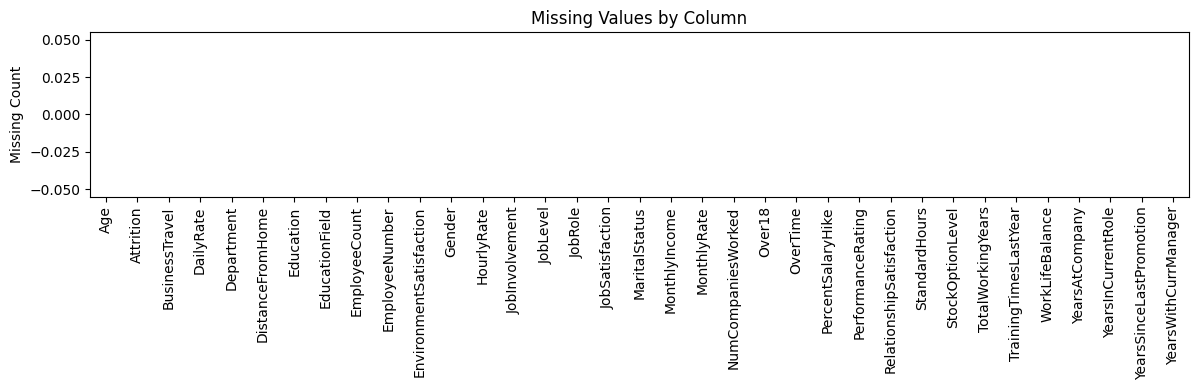

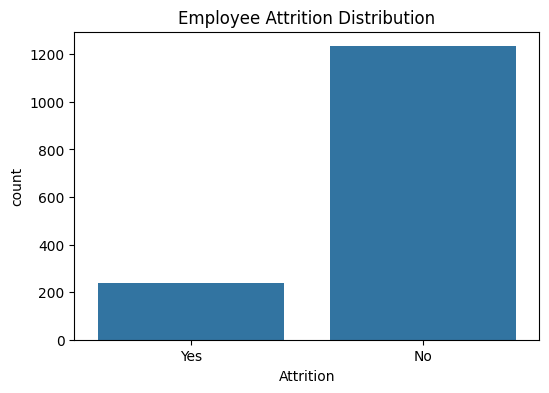

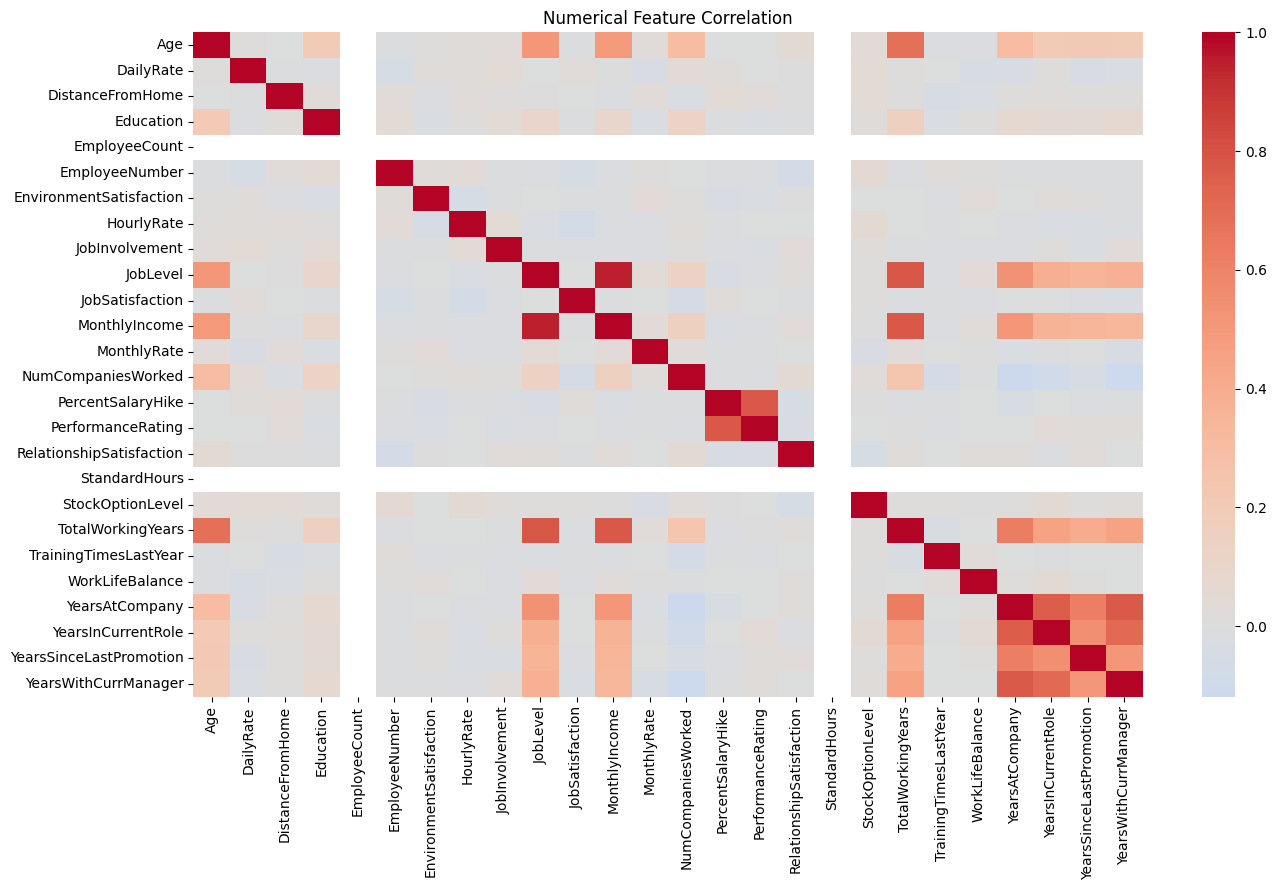

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# Missing values visualization
plt.figure(figsize=(12, 4))
df.isnull().sum().plot(kind="bar")
plt.title("Missing Values by Column")
plt.ylabel("Missing Count")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Attrition distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Attrition")
plt.title("Employee Attrition Distribution")
plt.show()

# Numerical correlation
plt.figure(figsize=(14, 9))
sns.heatmap(
    df.select_dtypes(include="number").corr(),
    cmap="coolwarm",
    center=0
)
plt.title("Numerical Feature Correlation")
plt.tight_layout()
plt.show()


In [ ]:

%%writefile /content/AutoPrep-AI/agents/data_quality_agent.py

import pandas as pd
import numpy as np


def run_data_quality_agent(df):
    """
    Inspect a dataset and return data-quality findings.
    This function does not modify the original dataframe.
    """

    if not isinstance(df, pd.DataFrame):
        raise TypeError("Input must be a pandas DataFrame.")

    if df.empty:
        raise ValueError("The dataset is empty.")

    report = {
        "total_rows": int(len(df)),
        "total_columns": int(len(df.columns)),
        "missing_values": {},
        "duplicate_rows": int(df.duplicated().sum()),
        "constant_columns": [],
        "possible_id_columns": [],
        "outliers": {},
        "data_types": {},
        "recommendations": []
    }

    # 1. Missing values
    missing = df.isnull().sum()
    report["missing_values"] = {
        col: int(count)
        for col, count in missing.items()
        if count > 0
    }

    # 2. Constant columns
    for col in df.columns:
        if df[col].nunique(dropna=False) <= 1:
            report["constant_columns"].append(col)

    # 3. Possible identifier columns
    for col in df.columns:
        unique_ratio = df[col].nunique(dropna=True) / max(len(df), 1)

        name_hint = any(
            word in col.lower()
            for word in ["id", "number", "code"]
        )

        if name_hint and unique_ratio >= 0.5:
            report["possible_id_columns"].append(col)

    # 4. Numerical outlier scan using IQR
    numeric_cols = df.select_dtypes(include=np.number).columns

    for col in numeric_cols:
        if col in report["possible_id_columns"]:
            continue

        series = df[col].dropna()

        if series.nunique() <= 2:
            continue

        q1 = series.quantile(0.25)
        q3 = series.quantile(0.75)
        iqr = q3 - q1

        if iqr == 0:
            continue

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        count = int(((series < lower) | (series > upper)).sum())

        if count > 0:
            report["outliers"][col] = {
                "count": count,
                "lower_bound": round(float(lower), 2),
                "upper_bound": round(float(upper), 2)
            }

    # 5. Data types
    report["data_types"] = {
        col: str(dtype)
        for col, dtype in df.dtypes.items()
    }

    # 6. Recommendations
    if report["missing_values"]:
        report["recommendations"].append(
            "Review missing values and choose suitable imputation or removal."
        )

    if report["duplicate_rows"] > 0:
        report["recommendations"].append(
            "Review duplicate rows before deciding whether to remove them."
        )

    if report["constant_columns"]:
        report["recommendations"].append(
            "Review constant columns; they may provide no predictive value."
        )

    if report["possible_id_columns"]:
        report["recommendations"].append(
            "Review identifier-like columns before model training."
        )

    if report["outliers"]:
        report["recommendations"].append(
            "Review detected outliers; do not remove them without domain justification."
        )

    if not report["recommendations"]:
        report["recommendations"].append(
            "No major structural data-quality issues were detected by these checks."
        )

    return report


def display_quality_report(report):
    print("=" * 60)
    print("          AUTOPREP AI - DATA QUALITY AGENT")
    print("=" * 60)

    print("\nDATASET")
    print("Rows:", report["total_rows"])
    print("Columns:", report["total_columns"])

    print("\nMISSING VALUES")
    print(report["missing_values"] or "None detected")

    print("\nDUPLICATE ROWS")
    print(report["duplicate_rows"])

    print("\nCONSTANT COLUMNS")
    print(report["constant_columns"] or "None detected")

    print("\nPOSSIBLE ID COLUMNS")
    print(report["possible_id_columns"] or "None detected")

    print("\nPOSSIBLE NUMERICAL OUTLIERS (IQR)")
    if report["outliers"]:
        for col, details in report["outliers"].items():
            print(
                f"{col}: {details['count']} rows "
                f"(bounds: {details['lower_bound']} to {details['upper_bound']})"
            )
    else:
        print("None detected")

    print("\nRECOMMENDATIONS")
    for number, recommendation in enumerate(
        report["recommendations"], start=1
    ):
        print(f"{number}. {recommendation}")


Writing /content/AutoPrep-AI/agents/data_quality_agent.py


In [ ]:

import sys
import pandas as pd

sys.path.insert(0, "/content/AutoPrep-AI")

from agents.data_quality_agent import (
    run_data_quality_agent,
    display_quality_report
)

DATA_PATH = "/content/AutoPrep-AI/data/employee_attrition.csv"

df = pd.read_csv(DATA_PATH)

quality_report = run_data_quality_agent(df)

display_quality_report(quality_report)


          AUTOPREP AI - DATA QUALITY AGENT

DATASET
Rows: 1470
Columns: 35

MISSING VALUES
None detected

DUPLICATE ROWS
0

CONSTANT COLUMNS
['EmployeeCount', 'Over18', 'StandardHours']

POSSIBLE ID COLUMNS
['EmployeeNumber']

POSSIBLE NUMERICAL OUTLIERS (IQR)
MonthlyIncome: 114 rows (bounds: -5291.0 to 16581.0)
NumCompaniesWorked: 52 rows (bounds: -3.5 to 8.5)
StockOptionLevel: 85 rows (bounds: -1.5 to 2.5)
TotalWorkingYears: 63 rows (bounds: -7.5 to 28.5)
TrainingTimesLastYear: 238 rows (bounds: 0.5 to 4.5)
YearsAtCompany: 104 rows (bounds: -6.0 to 18.0)
YearsInCurrentRole: 21 rows (bounds: -5.5 to 14.5)
YearsSinceLastPromotion: 107 rows (bounds: -4.5 to 7.5)
YearsWithCurrManager: 14 rows (bounds: -5.5 to 14.5)

RECOMMENDATIONS
1. Review constant columns; they may provide no predictive value.
2. Review identifier-like columns before model training.
3. Review detected outliers; do not remove them without domain justification.


In [ ]:

%%writefile /content/AutoPrep-AI/preprocessing/preprocessing_planner.py

import pandas as pd
import numpy as np

def create_preprocessing_plan(df, target_col="Attrition"):

    plan = {
        "dataset_shape": df.shape,
        "target_column": target_col,
        "actions": [],
        "warnings": [],
        "approval_required": True
    }

    # 1. Constant columns
    constant_columns = [
        col for col in df.columns
        if df[col].nunique(dropna=False) <= 1
    ]

    if constant_columns:
        plan["actions"].append({
            "operation": "Review constant columns",
            "columns": constant_columns,
            "recommendation": "Consider removing columns with only one unique value."
        })

    # 2. Identifier-like columns
    id_columns = []

    for col in df.columns:
        if col == target_col:
            continue

        if col.lower() in ["employeenumber", "id", "customerid", "recordid"]:
            id_columns.append(col)

    if id_columns:
        plan["actions"].append({
            "operation": "Review identifier columns",
            "columns": id_columns,
            "recommendation": "Consider excluding identifiers from model features."
        })

    # 3. Missing values
    missing_columns = df.columns[df.isnull().any()].tolist()

    if missing_columns:
        plan["actions"].append({
            "operation": "Handle missing values",
            "columns": missing_columns,
            "recommendation": "Use median for suitable numerical columns and mode for categorical columns."
        })
    else:
        plan["actions"].append({
            "operation": "Missing value handling",
            "columns": [],
            "recommendation": "No missing values detected. No imputation required."
        })

    # 4. Categorical encoding
    categorical_columns = df.select_dtypes(
        include=["object", "category", "bool"]
    ).columns.tolist()

    categorical_columns = [
        col for col in categorical_columns
        if col != target_col
    ]

    if categorical_columns:
        plan["actions"].append({
            "operation": "Categorical encoding",
            "columns": categorical_columns,
            "recommendation": "Use suitable encoding, such as one-hot encoding for nominal categories."
        })

    # 5. Numerical scaling
    excluded_columns = set(
        constant_columns + id_columns + [target_col]
    )

    numerical_columns = [
        col for col in df.select_dtypes(include=np.number).columns
        if col not in excluded_columns
    ]

    if numerical_columns:
        plan["actions"].append({
            "operation": "Numerical scaling",
            "columns": numerical_columns,
            "recommendation": "Consider StandardScaler or RobustScaler. Fit scalers only on training data."
        })

    # 6. Outlier handling
    outlier_columns = []

    for col in numerical_columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        count = int(((df[col] < lower) | (df[col] > upper)).sum())

        if count > 0:
            outlier_columns.append({
                "column": col,
                "count": count
            })

    plan["actions"].append({
        "operation": "Outlier review",
        "columns": outlier_columns,
        "recommendation": "Review outliers using domain knowledge. Do not automatically delete valid observations."
    })

    # 7. Target protection
    plan["warnings"].append(
        f"Protect target column '{target_col}'. Do not include it in feature transformations."
    )

    plan["warnings"].append(
        "Perform train/test split before fitting encoders, imputers, or scalers to prevent data leakage."
    )

    return plan


def display_preprocessing_plan(plan):

    print("=" * 60)
    print("       AUTOPREP AI - PREPROCESSING PLAN")
    print("=" * 60)

    print("\nDataset Shape:", plan["dataset_shape"])
    print("Target Column:", plan["target_column"])

    for index, action in enumerate(plan["actions"], start=1):
        print(f"\n{index}. {action['operation']}")
        print("Columns:", action["columns"])
        print("Recommendation:", action["recommendation"])

    print("\nIMPORTANT WARNINGS")

    for warning in plan["warnings"]:
        print("-", warning)

    print("\nApproval Required:", plan["approval_required"])
    print("\nNo dataset changes have been made.")


Writing /content/AutoPrep-AI/preprocessing/preprocessing_planner.py


In [ ]:

import sys
import pandas as pd

sys.path.insert(0, "/content/AutoPrep-AI")

from preprocessing.preprocessing_planner import (
    create_preprocessing_plan,
    display_preprocessing_plan
)

DATA_PATH = "/content/AutoPrep-AI/data/employee_attrition.csv"

df = pd.read_csv(DATA_PATH)

preprocessing_plan = create_preprocessing_plan(
    df,
    target_col="Attrition"
)

display_preprocessing_plan(preprocessing_plan)


       AUTOPREP AI - PREPROCESSING PLAN

Dataset Shape: (1470, 35)
Target Column: Attrition

1. Review constant columns
Columns: ['EmployeeCount', 'Over18', 'StandardHours']
Recommendation: Consider removing columns with only one unique value.

2. Review identifier columns
Columns: ['EmployeeNumber']
Recommendation: Consider excluding identifiers from model features.

3. Missing value handling
Columns: []
Recommendation: No missing values detected. No imputation required.

4. Categorical encoding
Columns: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'Over18', 'OverTime']
Recommendation: Use suitable encoding, such as one-hot encoding for nominal categories.

5. Numerical scaling
Columns: ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisf

In [ ]:

%%writefile /content/AutoPrep-AI/preprocessing/preprocessing_engine.py

import os
import json
import joblib
import numpy as np
import pandas as pd

from scipy.sparse import issparse

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer


def run_preprocessing(
    df,
    target_col="Attrition",
    approve=False
):

    if not approve:
        raise PermissionError(
            "Preprocessing requires explicit user approval."
        )

    if target_col not in df.columns:
        raise ValueError(f"Target column '{target_col}' not found.")

    # Preserve original dataframe
    data = df.copy(deep=True)

    # Identify constant columns
    constant_cols = [
        col for col in data.columns
        if col != target_col
        and data[col].nunique(dropna=False) <= 1
    ]

    # Identify ID columns
    id_cols = [
        col for col in data.columns
        if col.lower() in [
            "employeenumber",
            "employeeid",
            "customerid",
            "recordid"
        ]
    ]

    # Exclude these from model features only
    excluded_cols = list(set(constant_cols + id_cols))

    X = data.drop(
        columns=[target_col] + excluded_cols
    )

    y = data[target_col].copy()

    # Convert Yes/No target to 1/0
    if y.dtype == "object":
        normalized = y.astype(str).str.strip().str.lower()

        if set(normalized.unique()).issubset({"yes", "no"}):
            y = normalized.map({"no": 0, "yes": 1})

    # Encode other categorical targets if necessary
    if y.dtype == "object":
        encoder = LabelEncoder()
        y = pd.Series(
            encoder.fit_transform(y),
            name=target_col
        )
    else:
        encoder = None

    # Detect feature types
    numerical_cols = X.select_dtypes(
        include=np.number
    ).columns.tolist()

    categorical_cols = X.select_dtypes(
        include=["object", "category", "bool"]
    ).columns.tolist()

    transformers = []

    # Numerical preprocessing
    if numerical_cols:
        numerical_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ])

        transformers.append(
            ("numerical", numerical_pipeline, numerical_cols)
        )

    # Categorical preprocessing
    if categorical_cols:
        categorical_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ])

        transformers.append(
            ("categorical", categorical_pipeline, categorical_cols)
        )

    if not transformers:
        raise ValueError("No usable feature columns found.")

    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )

    # Split BEFORE fitting preprocessing transformations
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )

    # Fit only on training data
    X_train_processed = preprocessor.fit_transform(X_train)

    # Test data only receives the learned transformations
    X_test_processed = preprocessor.transform(X_test)

    # Convert sparse matrices if needed
    if issparse(X_train_processed):
        X_train_processed = X_train_processed.toarray()

    if issparse(X_test_processed):
        X_test_processed = X_test_processed.toarray()

    feature_names = preprocessor.get_feature_names_out()

    train_df = pd.DataFrame(
        X_train_processed,
        columns=feature_names
    )

    test_df = pd.DataFrame(
        X_test_processed,
        columns=feature_names
    )

    train_df[target_col] = np.asarray(y_train)
    test_df[target_col] = np.asarray(y_test)

    # Save outputs separately
    output_dir = "/content/AutoPrep-AI/data/processed"
    os.makedirs(output_dir, exist_ok=True)

    train_df.to_csv(
        os.path.join(output_dir, "train_processed.csv"),
        index=False
    )

    test_df.to_csv(
        os.path.join(output_dir, "test_processed.csv"),
        index=False
    )

    joblib.dump(
        preprocessor,
        os.path.join(output_dir, "preprocessing_pipeline.joblib")
    )

    if encoder is not None:
        joblib.dump(
            encoder,
            os.path.join(output_dir, "target_encoder.joblib")
        )

    # Save transformation information
    report = {
        "original_rows": int(len(data)),
        "original_columns": int(len(data.columns)),
        "constant_columns_excluded": constant_cols,
        "id_columns_excluded": id_cols,
        "numerical_columns": numerical_cols,
        "categorical_columns": categorical_cols,
        "training_rows": int(len(train_df)),
        "testing_rows": int(len(test_df)),
        "output_features": len(feature_names),
        "target_column": target_col,
        "target_values": sorted(
            pd.Series(y).dropna().unique().tolist()
        )
    }

    with open(
        os.path.join(output_dir, "preprocessing_report.json"),
        "w"
    ) as file:
        json.dump(report, file, indent=4)

    print("=" * 55)
    print("AUTOPREP AI - PREPROCESSING ENGINE")
    print("=" * 55)

    print("Original Dataset:", data.shape)
    print("Training Dataset:", train_df.shape)
    print("Testing Dataset:", test_df.shape)
    print("Excluded Constant Columns:", constant_cols)
    print("Excluded ID Columns:", id_cols)
    print("Numerical Features:", len(numerical_cols))
    print("Categorical Features:", len(categorical_cols))
    print("Final Features:", len(feature_names))

    print("\nFiles saved at:", output_dir)

    return {
        "train": train_df,
        "test": test_df,
        "preprocessor": preprocessor,
        "report": report
    }


Writing /content/AutoPrep-AI/preprocessing/preprocessing_engine.py


In [ ]:

import sys
import pandas as pd

sys.path.insert(0, "/content/AutoPrep-AI")

from preprocessing.preprocessing_engine import run_preprocessing

df = pd.read_csv(
    "/content/AutoPrep-AI/data/employee_attrition.csv"
)

results = run_preprocessing(
    df,
    target_col="Attrition",
    approve=True
)


AUTOPREP AI - PREPROCESSING ENGINE
Original Dataset: (1470, 35)
Training Dataset: (1176, 52)
Testing Dataset: (294, 52)
Excluded Constant Columns: ['EmployeeCount', 'Over18', 'StandardHours']
Excluded ID Columns: ['EmployeeNumber']
Numerical Features: 23
Categorical Features: 7
Final Features: 51

Files saved at: /content/AutoPrep-AI/data/processed


In [ ]:

import os

engine_path = "/content/AutoPrep-AI/preprocessing/preprocessing_engine.py"

if os.path.exists(engine_path):
    print("Preprocessing Engine file found!")
else:
    print("File not found. Please run the Step 8.1 code again.")


Preprocessing Engine file found!


In [ ]:

!pip install -q pandas numpy scikit-learn scipy joblib
print("Required libraries installed successfully!")


Required libraries installed successfully!


In [ ]:

import sys
import pandas as pd

sys.path.insert(0, "/content/AutoPrep-AI")

from preprocessing.preprocessing_engine import run_preprocessing

# Load original dataset
DATA_PATH = "/content/AutoPrep-AI/data/employee_attrition.csv"

df = pd.read_csv(DATA_PATH)

print("Original Dataset:", df.shape)

# Execute approved preprocessing
results = run_preprocessing(
    df,
    target_col="Attrition",
    approve=True
)


Original Dataset: (1470, 35)
AUTOPREP AI - PREPROCESSING ENGINE
Original Dataset: (1470, 35)
Training Dataset: (1176, 52)
Testing Dataset: (294, 52)
Excluded Constant Columns: ['EmployeeCount', 'Over18', 'StandardHours']
Excluded ID Columns: ['EmployeeNumber']
Numerical Features: 23
Categorical Features: 7
Final Features: 51

Files saved at: /content/AutoPrep-AI/data/processed


In [ ]:

import os

OUTPUT_DIR = "/content/AutoPrep-AI/data/processed"

print("GENERATED FILES")
print("=" * 40)

for file in os.listdir(OUTPUT_DIR):
    print("✓", file)

train_df = pd.read_csv(
    OUTPUT_DIR + "/train_processed.csv"
)

test_df = pd.read_csv(
    OUTPUT_DIR + "/test_processed.csv"
)

print("\nTraining shape:", train_df.shape)
print("Testing shape:", test_df.shape)

print("\nTraining dataset preview:")
display(train_df.head())


GENERATED FILES
✓ preprocessing_pipeline.joblib
✓ train_processed.csv
✓ preprocessing_report.json
✓ test_processed.csv

Training shape: (1176, 52)
Testing shape: (294, 52)

Training dataset preview:


,numerical__Age,numerical__DailyRate,numerical__DistanceFromHome,numerical__Education,numerical__EnvironmentSatisfaction,numerical__HourlyRate,numerical__JobInvolvement,numerical__JobLevel,numerical__JobSatisfaction,numerical__MonthlyIncome,...,categorical__JobRole_Research Director,categorical__JobRole_Research Scientist,categorical__JobRole_Sales Executive,categorical__JobRole_Sales Representative,categorical__MaritalStatus_Divorced,categorical__MaritalStatus_Married,categorical__MaritalStatus_Single,categorical__OverTime_No,categorical__OverTime_Yes,Attrition
0,1.090194,1.049455,-0.899915,1.064209,-0.658710,-0.908436,1.795282,1.762189,-0.647997,2.026752,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0
1,-1.634828,-0.523449,-0.899915,-1.855332,0.260202,1.694111,0.373564,-0.986265,1.153526,-0.864408,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0
2,0.981193,-0.992080,-0.777610,-1.855332,-1.577622,-0.662913,0.373564,1.762189,0.252765,2.347706,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0
3,-1.307825,-0.453653,0.445433,-1.855332,-0.658710,-1.252169,0.373564,-0.986265,0.252765,-0.956202,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0
4,0.654191,0.491086,-0.043784,2.037390,1.179114,0.319180,0.373564,-0.070114,0.252765,-0.185956,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0


In [ ]:

%%writefile /content/AutoPrep-AI/agents/feature_engineering_agent.py

import os
import json
import numpy as np
import pandas as pd

from sklearn.feature_selection import mutual_info_classif


def analyze_features(
    df,
    target_col="Attrition",
    correlation_threshold=0.90,
    variance_threshold=0.01
):

    if target_col not in df.columns:
        raise ValueError(f"Target column '{target_col}' not found.")

    X = df.drop(columns=[target_col]).copy()
    y = df[target_col].copy()

    # Keep numerical input features only
    X = X.select_dtypes(include=np.number)

    if X.empty:
        raise ValueError("No numerical features available.")

    # 1. Variance analysis
    variances = X.var()

    low_variance_features = variances[
        variances < variance_threshold
    ].index.tolist()

    # 2. Correlation analysis
    correlation_matrix = X.corr().abs()

    upper_triangle = correlation_matrix.where(
        np.triu(
            np.ones(correlation_matrix.shape),
            k=1
        ).astype(bool)
    )

    highly_correlated_pairs = []

    for column in upper_triangle.columns:
        for index in upper_triangle.index:
            value = upper_triangle.loc[index, column]

            if pd.notna(value) and value >= correlation_threshold:
                highly_correlated_pairs.append({
                    "feature_1": index,
                    "feature_2": column,
                    "correlation": round(float(value), 4)
                })

    # 3. Feature importance using mutual information
    importance_results = []

    if y.nunique() >= 2:
        scores = mutual_info_classif(
            X.fillna(0),
            y,
            random_state=42
        )

        importance_results = [
            {
                "feature": feature,
                "score": round(float(score), 5)
            }
            for feature, score in zip(X.columns, scores)
        ]

        importance_results.sort(
            key=lambda item: item["score"],
            reverse=True
        )

    # 4. Generate recommendations
    recommendations = []

    if low_variance_features:
        recommendations.append(
            "Review low-variance features before considering removal."
        )

    if highly_correlated_pairs:
        recommendations.append(
            "Review highly correlated feature pairs for redundancy."
        )

    if importance_results:
        recommendations.append(
            "Use feature importance scores to guide feature selection."
        )

    if not recommendations:
        recommendations.append(
            "No immediate feature selection concerns detected."
        )

    recommendations.append(
        "Do not remove features automatically. Obtain user approval first."
    )

    # 5. Report
    report = {
        "total_features": int(X.shape[1]),
        "target_column": target_col,
        "low_variance_features": low_variance_features,
        "highly_correlated_pairs": highly_correlated_pairs,
        "top_10_features": importance_results[:10],
        "recommendations": recommendations
    }

    return report


def display_feature_report(report):

    print("=" * 60)
    print("       AUTOPREP AI - FEATURE ENGINEERING AGENT")
    print("=" * 60)

    print("\nTotal Input Features:", report["total_features"])

    print("\n1. LOW VARIANCE FEATURES")
    print("-" * 40)

    if report["low_variance_features"]:
        for feature in report["low_variance_features"]:
            print("-", feature)
    else:
        print("No low-variance features detected.")

    print("\n2. HIGHLY CORRELATED FEATURE PAIRS")
    print("-" * 40)

    if report["highly_correlated_pairs"]:
        for pair in report["highly_correlated_pairs"]:
            print(
                pair["feature_1"],
                "<->",
                pair["feature_2"],
                "| Correlation:",
                pair["correlation"]
            )
    else:
        print("No highly correlated pairs detected.")

    print("\n3. TOP 10 FEATURES")
    print("-" * 40)

    for item in report["top_10_features"]:
        print(
            item["feature"],
            "| Score:",
            item["score"]
        )

    print("\n4. RECOMMENDATIONS")
    print("-" * 40)

    for recommendation in report["recommendations"]:
        print("-", recommendation)

    print("\nNo features have been removed or modified.")


Writing /content/AutoPrep-AI/agents/feature_engineering_agent.py


In [ ]:

import sys
import os
import json
import pandas as pd

sys.path.insert(0, "/content/AutoPrep-AI")

from agents.feature_engineering_agent import (
    analyze_features,
    display_feature_report
)

TRAIN_PATH = (
    "/content/AutoPrep-AI/data/processed/"
    "train_processed.csv"
)

train_df = pd.read_csv(TRAIN_PATH)

feature_report = analyze_features(
    train_df,
    target_col="Attrition",
    correlation_threshold=0.90,
    variance_threshold=0.01
)

display_feature_report(feature_report)

# Save feature engineering report
REPORT_PATH = (
    "/content/AutoPrep-AI/reports/"
    "feature_engineering_report.json"
)

os.makedirs(
    "/content/AutoPrep-AI/reports",
    exist_ok=True
)

with open(REPORT_PATH, "w") as file:
    json.dump(feature_report, file, indent=4)

print("\nFeature report saved:", REPORT_PATH)


       AUTOPREP AI - FEATURE ENGINEERING AGENT

Total Input Features: 51

1. LOW VARIANCE FEATURES
----------------------------------------
No low-variance features detected.

2. HIGHLY CORRELATED FEATURE PAIRS
----------------------------------------
numerical__JobLevel <-> numerical__MonthlyIncome | Correlation: 0.947
categorical__Department_Research & Development <-> categorical__Department_Sales | Correlation: 0.9117
categorical__Gender_Female <-> categorical__Gender_Male | Correlation: 1.0
categorical__Department_Human Resources <-> categorical__JobRole_Human Resources | Correlation: 0.9214
categorical__OverTime_No <-> categorical__OverTime_Yes | Correlation: 1.0

3. TOP 10 FEATURES
----------------------------------------
numerical__TotalWorkingYears | Score: 0.04903
numerical__MonthlyIncome | Score: 0.03678
numerical__JobLevel | Score: 0.03464
categorical__JobRole_Sales Representative | Score: 0.03236
categorical__OverTime_Yes | Score: 0.02687
categorical__JobRole_Research Direc

In [ ]:

%%writefile /content/AutoPrep-AI/agents/validation_agent.py

import os
import json
import numpy as np
import pandas as pd
import joblib

from sklearn.model_selection import train_test_split


def validate_preprocessing(project_dir):

    data_dir = os.path.join(project_dir, "data")
    processed_dir = os.path.join(data_dir, "processed")

    original_path = os.path.join(
        data_dir, "employee_attrition.csv"
    )

    train_path = os.path.join(
        processed_dir, "train_processed.csv"
    )

    test_path = os.path.join(
        processed_dir, "test_processed.csv"
    )

    pipeline_path = os.path.join(
        processed_dir, "preprocessing_pipeline.joblib"
    )

    # Load datasets
    original = pd.read_csv(original_path)
    train = pd.read_csv(train_path)
    test = pd.read_csv(test_path)

    preprocessor = joblib.load(pipeline_path)

    target_col = "Attrition"

    checks = []

    def add_check(name, passed, details):
        checks.append({
            "check": name,
            "status": "PASS" if passed else "FAIL",
            "details": details
        })

    # 1. Dataset dimensions
    add_check(
        "Original dataset dimensions",
        original.shape == (1470, 35),
        str(original.shape)
    )

    add_check(
        "Training and testing row count",
        len(train) + len(test) == len(original),
        f"{len(train)} + {len(test)} = {len(original)}"
    )

    add_check(
        "80/20 train-test split",
        len(train) == 1176 and len(test) == 294,
        f"Training: {len(train)}, Testing: {len(test)}"
    )

    # 2. Target column
    add_check(
        "Target column exists",
        target_col in train.columns and target_col in test.columns,
        target_col
    )

    # 3. Feature consistency
    train_features = train.drop(columns=[target_col])
    test_features = test.drop(columns=[target_col])

    add_check(
        "Training/testing feature consistency",
        train_features.columns.tolist() ==
        test_features.columns.tolist(),
        f"{len(train_features.columns)} features"
    )

    add_check(
        "Feature count matches pipeline",
        len(train_features.columns) ==
        len(preprocessor.get_feature_names_out()),
        f"Pipeline features: {len(preprocessor.get_feature_names_out())}"
    )

    # 4. Missing values
    add_check(
        "No missing values in training data",
        not train.isnull().any().any(),
        f"Missing cells: {int(train.isnull().sum().sum())}"
    )

    add_check(
        "No missing values in testing data",
        not test.isnull().any().any(),
        f"Missing cells: {int(test.isnull().sum().sum())}"
    )

    # 5. Duplicate rows
    add_check(
        "No duplicate training rows",
        train.duplicated().sum() == 0,
        f"Duplicates: {int(train.duplicated().sum())}"
    )

    add_check(
        "No duplicate testing rows",
        test.duplicated().sum() == 0,
        f"Duplicates: {int(test.duplicated().sum())}"
    )

    # 6. Numerical validity
    train_values = train_features.to_numpy(dtype=float)
    test_values = test_features.to_numpy(dtype=float)

    add_check(
        "Training features contain finite values",
        np.isfinite(train_values).all(),
        "Checked NaN and infinite numerical values"
    )

    add_check(
        "Testing features contain finite values",
        np.isfinite(test_values).all(),
        "Checked NaN and infinite numerical values"
    )

    # 7. Target values
    valid_targets = set(train[target_col].unique()).issubset({0, 1})
    valid_targets = valid_targets and set(
        test[target_col].unique()
    ).issubset({0, 1})

    add_check(
        "Target encoding validity",
        valid_targets,
        "Attrition encoded as 0 and 1"
    )

    # 8. Verify saved pipeline using reconstructed test split
    excluded = [
        col for col in original.columns
        if col != target_col and
        (
            original[col].nunique(dropna=False) <= 1
            or col.lower() in [
                "employeenumber",
                "employeeid",
                "customerid",
                "recordid"
            ]
        )
    ]

    X = original.drop(
        columns=[target_col] + excluded
    )

    y = original[target_col].copy()

    y = y.astype(str).str.strip().str.lower().map({
        "no": 0,
        "yes": 1
    })

    _, X_test_raw, _, y_test_raw = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )

    transformed_test = preprocessor.transform(X_test_raw)

    if hasattr(transformed_test, "toarray"):
        transformed_test = transformed_test.toarray()

    saved_test_values = test_features.to_numpy(dtype=float)

    pipeline_matches = np.allclose(
        transformed_test,
        saved_test_values,
        rtol=1e-5,
        atol=1e-6
    )

    add_check(
        "Saved pipeline reproduces test features",
        pipeline_matches,
        "Re-transformed test features compared with saved test CSV"
    )

    # 9. Original dataset structure
    add_check(
        "Original dataset structure preserved",
        original.shape == (1470, 35),
        "Original CSV loaded with expected dimensions"
    )

    # 10. Save validation report
    passed = sum(
        item["status"] == "PASS" for item in checks
    )

    failed = len(checks) - passed

    report = {
        "total_checks": len(checks),
        "passed": passed,
        "failed": failed,
        "overall_status": "PASS" if failed == 0 else "REVIEW REQUIRED",
        "checks": checks
    }

    report_dir = os.path.join(project_dir, "reports")
    os.makedirs(report_dir, exist_ok=True)

    report_path = os.path.join(
        report_dir, "validation_report.json"
    )

    with open(report_path, "w") as file:
        json.dump(report, file, indent=4)

    # Display results
    print("=" * 60)
    print("       AUTOPREP AI - VALIDATION AGENT")
    print("=" * 60)

    for item in checks:
        symbol = "✓" if item["status"] == "PASS" else "✗"

        print(f"\n{symbol} {item['check']}")
        print("  Status:", item["status"])
        print("  Details:", item["details"])

    print("\n" + "=" * 60)
    print("VALIDATION SUMMARY")
    print("=" * 60)

    print("Total Checks:", len(checks))
    print("Passed:", passed)
    print("Failed:", failed)
    print("Overall Status:", report["overall_status"])
    print("Report Saved:", report_path)

    return report


Writing /content/AutoPrep-AI/agents/validation_agent.py


In [ ]:

import sys

sys.path.insert(0, "/content/AutoPrep-AI")

from agents.validation_agent import validate_preprocessing

validation_report = validate_preprocessing(
    "/content/AutoPrep-AI"
)


       AUTOPREP AI - VALIDATION AGENT

✓ Original dataset dimensions
  Status: PASS
  Details: (1470, 35)

✓ Training and testing row count
  Status: PASS
  Details: 1176 + 294 = 1470

✓ 80/20 train-test split
  Status: PASS
  Details: Training: 1176, Testing: 294

✓ Target column exists
  Status: PASS
  Details: Attrition

✓ Training/testing feature consistency
  Status: PASS
  Details: 51 features

✓ Feature count matches pipeline
  Status: PASS
  Details: Pipeline features: 51

✓ No missing values in training data
  Status: PASS
  Details: Missing cells: 0

✓ No missing values in testing data
  Status: PASS
  Details: Missing cells: 0

✓ No duplicate training rows
  Status: PASS
  Details: Duplicates: 0

✓ No duplicate testing rows
  Status: PASS
  Details: Duplicates: 0

✓ Training features contain finite values
  Status: PASS
  Details: Checked NaN and infinite numerical values

✓ Testing features contain finite values
  Status: PASS
  Details: Checked NaN and infinite numerical v

In [ ]:

%%writefile /content/AutoPrep-AI/agents/report_agent.py

import os
import json
import pandas as pd
from datetime import datetime


def generate_final_report(project_dir):

    data_dir = os.path.join(project_dir, "data")
    processed_dir = os.path.join(data_dir, "processed")
    reports_dir = os.path.join(project_dir, "reports")

    os.makedirs(reports_dir, exist_ok=True)

    # Load source datasets
    original = pd.read_csv(
        os.path.join(data_dir, "employee_attrition.csv")
    )

    train = pd.read_csv(
        os.path.join(processed_dir, "train_processed.csv")
    )

    test = pd.read_csv(
        os.path.join(processed_dir, "test_processed.csv")
    )

    # Load previous agent reports
    def load_json(filename):
        path = os.path.join(reports_dir, filename)

        if os.path.exists(path):
            with open(path, "r") as file:
                return json.load(file)

        return {}

    preprocessing = load_json("preprocessing_report.json")
    feature_report = load_json("feature_engineering_report.json")
    validation = load_json("validation_report.json")

    # Dataset statistics
    target_distribution = (
        original["Attrition"]
        .value_counts()
        .to_dict()
    )

    missing_total = int(original.isnull().sum().sum())
    duplicate_total = int(original.duplicated().sum())

    constant_columns = [
        col for col in original.columns
        if original[col].nunique(dropna=False) <= 1
    ]

    # Build final report data
    report = {
        "project": "AutoPrep AI",
        "title": "Multi-Agent Intelligent Data Preprocessing System",
        "generated_at": datetime.now().isoformat(timespec="seconds"),
        "dataset": {
            "original_rows": int(original.shape[0]),
            "original_columns": int(original.shape[1]),
            "training_rows": int(train.shape[0]),
            "testing_rows": int(test.shape[0]),
            "processed_features": int(train.shape[1] - 1),
            "target_column": "Attrition",
            "target_distribution": {
                str(k): int(v)
                for k, v in target_distribution.items()
            }
        },
        "data_quality": {
            "missing_values": missing_total,
            "duplicate_rows": duplicate_total,
            "constant_columns": constant_columns
        },
        "preprocessing": preprocessing,
        "feature_engineering": feature_report,
        "validation": validation
    }

    # Markdown report
    lines = [
        "# AutoPrep AI – Final Project Report",
        "",
        f"Generated: {report['generated_at']}",
        "",
        "## 1. Project Overview",
        "",
        "AutoPrep AI is a multi-stage intelligent data preprocessing project.",
        "It analyzes data quality, prepares preprocessing recommendations,",
        "transforms approved features, performs feature analysis, and validates",
        "the resulting training and testing datasets.",
        "",
        "## 2. Dataset Overview",
        "",
        f"- Original rows: {original.shape[0]}",
        f"- Original columns: {original.shape[1]}",
        f"- Training rows: {train.shape[0]}",
        f"- Testing rows: {test.shape[0]}",
        f"- Processed input features: {train.shape[1] - 1}",
        "- Target: Attrition",
        "",
        "### Target Distribution",
        ""
    ]

    for label, count in target_distribution.items():
        lines.append(f"- {label}: {count}")

    lines.extend([
        "",
        "## 3. Data Quality Findings",
        "",
        f"- Missing values: {missing_total}",
        f"- Duplicate rows: {duplicate_total}",
        f"- Constant columns: {', '.join(constant_columns) or 'None'}",
        "",
        "## 4. Preprocessing",
        "",
        f"- Numerical features: {len(preprocessing.get('numerical_columns', []))}",
        f"- Categorical features: {len(preprocessing.get('categorical_columns', []))}",
        f"- Excluded constant columns: {', '.join(preprocessing.get('constant_columns_excluded', [])) or 'None'}",
        f"- Excluded identifier columns: {', '.join(preprocessing.get('id_columns_excluded', [])) or 'None'}",
        "- Numerical imputation: Median, if required",
        "- Categorical imputation: Most frequent, if required",
        "- Categorical encoding: One-hot encoding",
        "- Numerical scaling: StandardScaler",
        "- Outlier values: Preserved",
        "- Target column: Preserved separately",
        "",
        "## 5. Feature Engineering Findings",
        "",
        f"- Input features analyzed: {feature_report.get('total_features', 'Not available')}",
        f"- Low-variance features: {len(feature_report.get('low_variance_features', []))}",
        f"- Highly correlated pairs: {len(feature_report.get('highly_correlated_pairs', []))}",
        "",
        "### Top Features by Mutual Information",
        ""
    ])

    for item in feature_report.get("top_10_features", []):
        lines.append(
            f"- {item['feature']}: {item['score']}"
        )

    lines.extend([
        "",
        "## 6. Validation Results",
        "",
        f"- Total checks: {validation.get('total_checks', 0)}",
        f"- Passed: {validation.get('passed', 0)}",
        f"- Failed: {validation.get('failed', 0)}",
        f"- Overall status: {validation.get('overall_status', 'Not available')}",
        ""
    ])

    for check in validation.get("checks", []):
        lines.append(
            f"- [{check['status']}] {check['check']}: {check['details']}"
        )

    lines.extend([
        "",
        "## 7. Generated Artifacts",
        "",
        "- train_processed.csv",
        "- test_processed.csv",
        "- preprocessing_pipeline.joblib",
        "- preprocessing_report.json",
        "- feature_engineering_report.json",
        "- validation_report.json",
        "",
        "## 8. Limitations and Future Improvements",
        "",
        "- Add an interactive Streamlit dashboard.",
        "- Integrate the agents through a central orchestrator.",
        "- Add user-controlled feature selection.",
        "- Add configurable scaling and outlier treatment.",
        "- Add downloadable PDF and Excel reports.",
        "- Add model training and evaluation as a separate stage.",
        "",
        "## 9. Conclusion",
        "",
        "The preprocessing workflow produced separate training and testing",
        "datasets. The validation report should be reviewed before using these",
        "datasets for downstream machine learning."
    ])

    markdown_report = "\n".join(lines)

    # Save Markdown report
    markdown_path = os.path.join(
        reports_dir, "autoprep_final_report.md"
    )

    with open(markdown_path, "w", encoding="utf-8") as file:
        file.write(markdown_report)

    # Save JSON report
    json_path = os.path.join(
        reports_dir, "autoprep_final_report.json"
    )

    with open(json_path, "w", encoding="utf-8") as file:
        json.dump(report, file, indent=4)

    # Save short summary
    summary_path = os.path.join(
        reports_dir, "autoprep_summary.txt"
    )

    summary = (
        "AUTOPREP AI - PROJECT SUMMARY\n"
        "=============================\n"
        f"Original dataset: {original.shape}\n"
        f"Training dataset: {train.shape}\n"
        f"Testing dataset: {test.shape}\n"
        f"Missing values: {missing_total}\n"
        f"Duplicate rows: {duplicate_total}\n"
        f"Validation: {validation.get('overall_status', 'Not available')}\n"
        f"Validation passed: {validation.get('passed', 0)}\n"
        f"Validation failed: {validation.get('failed', 0)}\n"
    )

    with open(summary_path, "w", encoding="utf-8") as file:
        file.write(summary)

    print("=" * 60)
    print("AUTOPREP AI - REPORT AGENT")
    print("=" * 60)
    print("\nFinal report generated successfully!")
    print("Markdown:", markdown_path)
    print("JSON:", json_path)
    print("Summary:", summary_path)

    return report


Writing /content/AutoPrep-AI/agents/report_agent.py


In [ ]:

import sys

sys.path.insert(0, "/content/AutoPrep-AI")

from agents.report_agent import generate_final_report

final_report = generate_final_report(
    "/content/AutoPrep-AI"
)


AUTOPREP AI - REPORT AGENT

Final report generated successfully!
Markdown: /content/AutoPrep-AI/reports/autoprep_final_report.md
JSON: /content/AutoPrep-AI/reports/autoprep_final_report.json
Summary: /content/AutoPrep-AI/reports/autoprep_summary.txt


In [ ]:

import os

REPORT_DIR = "/content/AutoPrep-AI/reports"

print("AUTOPREP AI - REPORT FILES")
print("=" * 45)

for filename in os.listdir(REPORT_DIR):
    path = os.path.join(REPORT_DIR, filename)

    if os.path.isfile(path):
        print("✓", filename)

print("\nFINAL PROJECT SUMMARY")
print("=" * 45)

with open(
    os.path.join(REPORT_DIR, "autoprep_summary.txt"),
    "r"
) as file:
    print(file.read())


AUTOPREP AI - REPORT FILES
✓ feature_engineering_report.json
✓ autoprep_summary.txt
✓ autoprep_final_report.json
✓ autoprep_final_report.md
✓ validation_report.json

FINAL PROJECT SUMMARY
AUTOPREP AI - PROJECT SUMMARY
Original dataset: (1470, 35)
Training dataset: (1176, 52)
Testing dataset: (294, 52)
Missing values: 0
Duplicate rows: 0
Validation: PASS
Validation passed: 15
Validation failed: 0



In [ ]:

from google.colab import files

files.download(
    "/content/AutoPrep-AI/reports/autoprep_final_report.md"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import os

PROJECT = "/content/AutoPrep-AI"

folders = [
    "agents",
    "core",
    "preprocessing",
    "utils",
    "reports"
]

for folder in folders:
    path = os.path.join(PROJECT, folder)

    print("\n" + "=" * 45)
    print(folder.upper())
    print("=" * 45)

    if os.path.exists(path):
        for filename in sorted(os.listdir(path)):
            print("✓", filename)
    else:
        print("Folder not found")



AGENTS
✓ __init__.py
✓ __pycache__
✓ data_quality_agent.py
✓ feature_engineering_agent.py
✓ report_agent.py
✓ validation_agent.py

CORE
✓ __init__.py

PREPROCESSING
✓ __init__.py
✓ __pycache__
✓ preprocessing_engine.py
✓ preprocessing_planner.py

UTILS
✓ __init__.py
✓ __pycache__
✓ data_analyzer.py

REPORTS
✓ autoprep_final_report.json
✓ autoprep_final_report.md
✓ autoprep_summary.txt
✓ feature_engineering_report.json
✓ validation_report.json


In [ ]:

import ast
import os

PROJECT = "/content/AutoPrep-AI"

files_to_check = [
    "utils/data_analyzer.py",
    "agents/data_quality_agent.py",
    "preprocessing/preprocessing_planner.py",
    "preprocessing/preprocessing_engine.py",
    "agents/feature_engineering_agent.py",
    "agents/validation_agent.py",
    "agents/report_agent.py"
]

for relative_path in files_to_check:
    path = os.path.join(PROJECT, relative_path)

    print("\n" + "=" * 60)
    print("FILE:", relative_path)
    print("=" * 60)

    with open(path, "r") as f:
        source = f.read()

    tree = ast.parse(source)

    for node in tree.body:
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
            print("FUNCTION:", ast.unparse(node.args))
            print("NAME:", node.name)

        elif isinstance(node, ast.ClassDef):
            print("CLASS:", node.name)
            for item in node.body:
                if isinstance(item, ast.FunctionDef):
                    print("  METHOD:", item.name,
                          ast.unparse(item.args))



FILE: utils/data_analyzer.py
FUNCTION: df
NAME: analyze_dataset

FILE: agents/data_quality_agent.py
FUNCTION: df
NAME: run_data_quality_agent
FUNCTION: report
NAME: display_quality_report

FILE: preprocessing/preprocessing_planner.py
FUNCTION: df, target_col='Attrition'
NAME: create_preprocessing_plan
FUNCTION: plan
NAME: display_preprocessing_plan

FILE: preprocessing/preprocessing_engine.py
FUNCTION: df, target_col='Attrition', approve=False
NAME: run_preprocessing

FILE: agents/feature_engineering_agent.py
FUNCTION: df, target_col='Attrition', correlation_threshold=0.9, variance_threshold=0.01
NAME: analyze_features
FUNCTION: report
NAME: display_feature_report

FILE: agents/validation_agent.py
FUNCTION: project_dir
NAME: validate_preprocessing

FILE: agents/report_agent.py
FUNCTION: project_dir
NAME: generate_final_report


In [ ]:

import sys
import inspect

sys.path.insert(0, "/content/AutoPrep-AI")

from utils.data_analyzer import analyze_dataset
from agents.data_quality_agent import run_data_quality_agent
from preprocessing.preprocessing_planner import create_preprocessing_plan
from preprocessing.preprocessing_engine import run_preprocessing
from agents.feature_engineering_agent import analyze_features
from agents.validation_agent import validate_preprocessing
from agents.report_agent import generate_final_report

functions = [
    analyze_dataset,
    run_data_quality_agent,
    create_preprocessing_plan,
    run_preprocessing,
    analyze_features,
    validate_preprocessing,
    generate_final_report
]

for func in functions:
    print("\n" + "=" * 65)
    print("FUNCTION:", func.__name__)
    print("=" * 65)
    print(inspect.getsource(func))



FUNCTION: analyze_dataset
def analyze_dataset(df):

    print("=" * 55)
    print("       AUTOPREP AI - DATASET ANALYZER")
    print("=" * 55)

    # Dataset information
    rows, columns = df.shape

    print("\n1. DATASET OVERVIEW")
    print("-" * 40)
    print("Total Rows:", rows)
    print("Total Columns:", columns)
    print("Total Cells:", rows * columns)

    # Column classification
    numerical_columns = df.select_dtypes(
        include=np.number
    ).columns.tolist()

    categorical_columns = df.select_dtypes(
        include=["object", "category", "bool"]
    ).columns.tolist()

    print("\n2. COLUMN ANALYSIS")
    print("-" * 40)
    print("Numerical Columns:", len(numerical_columns))
    print("Categorical Columns:", len(categorical_columns))

    # Missing values
    missing_values = df.isnull().sum()
    missing_columns = missing_values[missing_values > 0]

    print("\n3. MISSING VALUE ANALYSIS")
    print("-" * 40)

    if len(missing_columns) == 0:
        print

In [ ]:

%%writefile /content/AutoPrep-AI/core/orchestrator.py

import os
import sys
import json
import shutil
import pandas as pd

PROJECT_DIR = "/content/AutoPrep-AI"

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

# Import existing project modules
from utils.data_analyzer import analyze_dataset
from agents.data_quality_agent import (
    run_data_quality_agent,
    display_quality_report
)
from preprocessing.preprocessing_planner import (
    create_preprocessing_plan,
    display_preprocessing_plan
)
from preprocessing.preprocessing_engine import run_preprocessing
from agents.feature_engineering_agent import analyze_features
from agents.validation_agent import validate_preprocessing
from agents.report_agent import generate_final_report


def run_autoprep_workflow(
    project_dir=PROJECT_DIR,
    target_col="Attrition",
    approve=False
):
    print("\n" + "=" * 65)
    print("       AUTOPREP AI - CENTRAL AGENT ORCHESTRATOR")
    print("=" * 65)

    data_path = os.path.join(
        project_dir, "data", "employee_attrition.csv"
    )

    if not os.path.exists(data_path):
        raise FileNotFoundError(
            f"Original dataset not found: {data_path}"
        )

    # Always load the original dataset
    df = pd.read_csv(data_path)

    if target_col not in df.columns:
        raise ValueError(
            f"Target column '{target_col}' not found."
        )

    state = {
        "project": "AutoPrep AI",
        "dataset_shape": df.shape,
        "target_column": target_col,
        "approval_received": approve,
        "stages_completed": [],
        "workflow_status": "RUNNING"
    }

    # --------------------------------------------------
    # AGENT 1: DATA ANALYST
    # --------------------------------------------------
    print("\n[1/7] DATA ANALYST AGENT")

    state["data_analysis"] = analyze_dataset(df)
    state["stages_completed"].append("Data Analyst")

    # --------------------------------------------------
    # AGENT 2: DATA QUALITY
    # --------------------------------------------------
    print("\n[2/7] DATA QUALITY AGENT")

    quality_report = run_data_quality_agent(df)

    display_quality_report(quality_report)

    state["data_quality"] = quality_report
    state["stages_completed"].append("Data Quality")

    # --------------------------------------------------
    # AGENT 3: PREPROCESSING PLANNER
    # --------------------------------------------------
    print("\n[3/7] PREPROCESSING PLANNER")

    preprocessing_plan = create_preprocessing_plan(
        df, target_col=target_col
    )

    display_preprocessing_plan(preprocessing_plan)

    state["preprocessing_plan"] = preprocessing_plan
    state["stages_completed"].append("Preprocessing Planner")

    # --------------------------------------------------
    # APPROVAL GATE
    # --------------------------------------------------
    if not approve:
        state["workflow_status"] = "WAITING_FOR_APPROVAL"

        print("\n" + "=" * 65)
        print("USER APPROVAL REQUIRED")
        print("=" * 65)
        print("The analysis and preprocessing plan are ready.")
        print("No preprocessing has been executed in this run.")
        print("Review the plan before approving transformations.")

        return state

    # --------------------------------------------------
    # AGENT 4: PREPROCESSING ENGINE
    # --------------------------------------------------
    print("\n[4/7] PREPROCESSING ENGINE")

    preprocessing_result = run_preprocessing(
        df,
        target_col=target_col,
        approve=True
    )

    state["preprocessing"] = preprocessing_result["report"]
    state["stages_completed"].append("Preprocessing Engine")

    # Make preprocessing report available to Report Agent
    processed_report = os.path.join(
        project_dir,
        "data",
        "processed",
        "preprocessing_report.json"
    )

    reports_dir = os.path.join(project_dir, "reports")
    os.makedirs(reports_dir, exist_ok=True)

    if os.path.exists(processed_report):
        shutil.copy2(
            processed_report,
            os.path.join(reports_dir, "preprocessing_report.json")
        )

    # --------------------------------------------------
    # AGENT 5: FEATURE ENGINEERING
    # --------------------------------------------------
    print("\n[5/7] FEATURE ENGINEERING AGENT")

    train_df = preprocessing_result["train"]

    feature_report = analyze_features(
        train_df,
        target_col=target_col
    )

    feature_report_path = os.path.join(
        reports_dir,
        "feature_engineering_report.json"
    )

    with open(feature_report_path, "w") as file:
        json.dump(feature_report, file, indent=4)

    state["feature_engineering"] = feature_report
    state["stages_completed"].append("Feature Engineering")

    # --------------------------------------------------
    # AGENT 6: VALIDATION
    # --------------------------------------------------
    print("\n[6/7] VALIDATION AGENT")

    validation_report = validate_preprocessing(project_dir)

    state["validation"] = validation_report
    state["stages_completed"].append("Validation")

    # --------------------------------------------------
    # AGENT 7: REPORT GENERATION
    # --------------------------------------------------
    print("\n[7/7] REPORT AGENT")

    final_report = generate_final_report(project_dir)

    state["final_report"] = final_report
    state["stages_completed"].append("Report Generation")

    # --------------------------------------------------
    # FINAL WORKFLOW STATUS
    # --------------------------------------------------
    if validation_report["failed"] == 0:
        state["workflow_status"] = "COMPLETED"
    else:
        state["workflow_status"] = "COMPLETED_WITH_WARNINGS"

    print("\n" + "=" * 65)
    print("AUTOPREP AI - WORKFLOW SUMMARY")
    print("=" * 65)

    print("Dataset:", state["dataset_shape"])
    print("Stages completed:", len(state["stages_completed"]))

    for stage in state["stages_completed"]:
        print("✓", stage)

    print("Validation:", validation_report["overall_status"])
    print("Workflow status:", state["workflow_status"])

    return state


Writing /content/AutoPrep-AI/core/orchestrator.py


In [ ]:

import sys

sys.path.insert(0, "/content/AutoPrep-AI")

from core.orchestrator import run_autoprep_workflow

workflow_state = run_autoprep_workflow(
    project_dir="/content/AutoPrep-AI",
    target_col="Attrition",
    approve=False
)

print("\nWORKFLOW STATUS:", workflow_state["workflow_status"])



       AUTOPREP AI - CENTRAL AGENT ORCHESTRATOR

[1/7] DATA ANALYST AGENT
       AUTOPREP AI - DATASET ANALYZER

1. DATASET OVERVIEW
----------------------------------------
Total Rows: 1470
Total Columns: 35
Total Cells: 51450

2. COLUMN ANALYSIS
----------------------------------------
Numerical Columns: 26
Categorical Columns: 9

3. MISSING VALUE ANALYSIS
----------------------------------------
No missing values detected!

4. DUPLICATE ANALYSIS
----------------------------------------
Duplicate Rows: 0

5. STATISTICAL SUMMARY
----------------------------------------
           Age  DailyRate  DistanceFromHome  Education  EmployeeCount  \
count  1470.00    1470.00           1470.00    1470.00         1470.0   
mean     36.92     802.49              9.19       2.91            1.0   
std       9.14     403.51              8.11       1.02            0.0   
min      18.00     102.00              1.00       1.00            1.0   
25%      30.00     465.00              2.00       2.00   

In [ ]:
import os
import pandas as pd
import hashlib

PROJECT_DIR = "/content/AutoPrep-AI"
ORIGINAL_FILE = os.path.join(
    PROJECT_DIR, "data", "employee_attrition.csv"
)

assert os.path.exists(ORIGINAL_FILE), "Original dataset not found!"

df_original = pd.read_csv(ORIGINAL_FILE)

print("Original dataset:", df_original.shape)
print("File size:", os.path.getsize(ORIGINAL_FILE), "bytes")

with open(ORIGINAL_FILE, "rb") as f:
    original_hash_before = hashlib.sha256(f.read()).hexdigest()

print("Original dataset integrity check: READY")

Original dataset: (1470, 35)
File size: 226503 bytes
Original dataset integrity check: READY


In [ ]:
import os
import shutil
from datetime import datetime

PROCESSED_DIR = os.path.join(PROJECT_DIR, "data", "processed")
BACKUP_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "backup_before_orchestrator"
)

os.makedirs(BACKUP_DIR, exist_ok=True)

if os.path.exists(PROCESSED_DIR):
    shutil.copytree(
        PROCESSED_DIR,
        BACKUP_DIR,
        dirs_exist_ok=True
    )

print("Backup location:", BACKUP_DIR)
print("Backup files:")

for root, dirs, files in os.walk(BACKUP_DIR):
    for filename in files:
        print("-", filename)

print("\nBackup completed.")

Backup location: /content/AutoPrep-AI/data/backup_before_orchestrator
Backup files:
- preprocessing_pipeline.joblib
- train_processed.csv
- preprocessing_report.json
- test_processed.csv

Backup completed.


In [ ]:
workflow_state = run_autoprep_workflow(
    project_dir="/content/AutoPrep-AI",
    target_col="Attrition",
    approve=True
)

print("\n========== FINAL WORKFLOW STATUS ==========")
print(workflow_state.get("status"))


       AUTOPREP AI - CENTRAL AGENT ORCHESTRATOR

[1/7] DATA ANALYST AGENT
       AUTOPREP AI - DATASET ANALYZER

1. DATASET OVERVIEW
----------------------------------------
Total Rows: 1470
Total Columns: 35
Total Cells: 51450

2. COLUMN ANALYSIS
----------------------------------------
Numerical Columns: 26
Categorical Columns: 9

3. MISSING VALUE ANALYSIS
----------------------------------------
No missing values detected!

4. DUPLICATE ANALYSIS
----------------------------------------
Duplicate Rows: 0

5. STATISTICAL SUMMARY
----------------------------------------
           Age  DailyRate  DistanceFromHome  Education  EmployeeCount  \
count  1470.00    1470.00           1470.00    1470.00         1470.0   
mean     36.92     802.49              9.19       2.91            1.0   
std       9.14     403.51              8.11       1.02            0.0   
min      18.00     102.00              1.00       1.00            1.0   
25%      30.00     465.00              2.00       2.00   

In [ ]:
print("Workflow status:", workflow_state.get("status"))

print("\nGenerated reports:")
for filename in os.listdir("/content/AutoPrep-AI/reports"):
    print("-", filename)

print("\nProcessed datasets:")
for filename in os.listdir("/content/AutoPrep-AI/data/processed"):
    print("-", filename)

Workflow status: None

Generated reports:
- feature_engineering_report.json
- autoprep_summary.txt
- autoprep_final_report.json
- autoprep_final_report.md
- preprocessing_report.json
- validation_report.json

Processed datasets:
- preprocessing_pipeline.joblib
- train_processed.csv
- preprocessing_report.json
- test_processed.csv


In [ ]:
print("Workflow state type:", type(workflow_state))

print("\nWorkflow state keys:")
if isinstance(workflow_state, dict):
    for key in workflow_state:
        print("-", key)

    print("\nComplete workflow state:")
    for key, value in workflow_state.items():
        print(f"\n{key}: {value}")
else:
    print(workflow_state)

Workflow state type: <class 'dict'>

Workflow state keys:
- project
- dataset_shape
- target_column
- approval_received
- stages_completed
- workflow_status
- data_analysis
- data_quality
- preprocessing_plan
- preprocessing
- feature_engineering
- validation
- final_report

Complete workflow state:

project: AutoPrep AI

dataset_shape: (1470, 35)

target_column: Attrition

approval_received: True

stages_completed: ['Data Analyst', 'Data Quality', 'Preprocessing Planner', 'Preprocessing Engine', 'Feature Engineering', 'Validation', 'Report Generation']

workflow_status: COMPLETED

data_analysis: {'rows': 1470, 'columns': 35, 'numerical_columns': ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'Tota

In [ ]:
import json
import os

validation_path = (
    "/content/AutoPrep-AI/reports/validation_report.json"
)

with open(validation_path, "r") as f:
    validation = json.load(f)

print(json.dumps(validation, indent=4))

{
    "total_checks": 15,
    "passed": 15,
    "failed": 0,
    "overall_status": "PASS",
    "checks": [
        {
            "check": "Original dataset dimensions",
            "status": "PASS",
            "details": "(1470, 35)"
        },
        {
            "check": "Training and testing row count",
            "status": "PASS",
            "details": "1176 + 294 = 1470"
        },
        {
            "check": "80/20 train-test split",
            "status": "PASS",
            "details": "Training: 1176, Testing: 294"
        },
        {
            "check": "Target column exists",
            "status": "PASS",
            "details": "Attrition"
        },
        {
            "check": "Training/testing feature consistency",
            "status": "PASS",
            "details": "51 features"
        },
        {
            "check": "Feature count matches pipeline",
            "status": "PASS",
            "details": "Pipeline features: 51"
        },
        {
          

In [ ]:
import hashlib
import pandas as pd

original_file = (
    "/content/AutoPrep-AI/data/employee_attrition.csv"
)

with open(original_file, "rb") as f:
    current_hash = hashlib.sha256(f.read()).hexdigest()

print("Original dataset dimensions:",
      pd.read_csv(original_file).shape)

if "original_hash_before" in globals():
    print("Original dataset unchanged:",
          current_hash == original_hash_before)
else:
    print("Previous hash unavailable. Dimensions checked instead.")

Original dataset dimensions: (1470, 35)
Original dataset unchanged: True


In [ ]:
import json

validation_path = "/content/AutoPrep-AI/reports/validation_report.json"

with open(validation_path, "r") as f:
    validation = json.load(f)

print(json.dumps(validation, indent=4))

{
    "total_checks": 15,
    "passed": 15,
    "failed": 0,
    "overall_status": "PASS",
    "checks": [
        {
            "check": "Original dataset dimensions",
            "status": "PASS",
            "details": "(1470, 35)"
        },
        {
            "check": "Training and testing row count",
            "status": "PASS",
            "details": "1176 + 294 = 1470"
        },
        {
            "check": "80/20 train-test split",
            "status": "PASS",
            "details": "Training: 1176, Testing: 294"
        },
        {
            "check": "Target column exists",
            "status": "PASS",
            "details": "Attrition"
        },
        {
            "check": "Training/testing feature consistency",
            "status": "PASS",
            "details": "51 features"
        },
        {
            "check": "Feature count matches pipeline",
            "status": "PASS",
            "details": "Pipeline features: 51"
        },
        {
          

In [ ]:
print("Workflow state keys:")
print(list(workflow_state.keys()))

print("\nWorkflow status:")
print(workflow_state.get("status"))

Workflow state keys:
['project', 'dataset_shape', 'target_column', 'approval_received', 'stages_completed', 'workflow_status', 'data_analysis', 'data_quality', 'preprocessing_plan', 'preprocessing', 'feature_engineering', 'validation', 'final_report']

Workflow status:
None


In [ ]:
print("Actual Workflow Status:",
      workflow_state.get("workflow_status"))

print("\nApproval Received:",
      workflow_state.get("approval_received"))

print("\nStages Completed:")
for stage in workflow_state.get("stages_completed", []):
    print("✅", stage)

Actual Workflow Status: COMPLETED

Approval Received: True

Stages Completed:
✅ Data Analyst
✅ Data Quality
✅ Preprocessing Planner
✅ Preprocessing Engine
✅ Feature Engineering
✅ Validation
✅ Report Generation


In [ ]:
print("Validation result:")
print(workflow_state.get("validation"))

Validation result:
{'total_checks': 15, 'passed': 15, 'failed': 0, 'overall_status': 'PASS', 'checks': [{'check': 'Original dataset dimensions', 'status': 'PASS', 'details': '(1470, 35)'}, {'check': 'Training and testing row count', 'status': 'PASS', 'details': '1176 + 294 = 1470'}, {'check': '80/20 train-test split', 'status': 'PASS', 'details': 'Training: 1176, Testing: 294'}, {'check': 'Target column exists', 'status': 'PASS', 'details': 'Attrition'}, {'check': 'Training/testing feature consistency', 'status': 'PASS', 'details': '51 features'}, {'check': 'Feature count matches pipeline', 'status': 'PASS', 'details': 'Pipeline features: 51'}, {'check': 'No missing values in training data', 'status': 'PASS', 'details': 'Missing cells: 0'}, {'check': 'No missing values in testing data', 'status': 'PASS', 'details': 'Missing cells: 0'}, {'check': 'No duplicate training rows', 'status': 'PASS', 'details': 'Duplicates: 0'}, {'check': 'No duplicate testing rows', 'status': 'PASS', 'details

In [ ]:

%%writefile /content/AutoPrep-AI/agents/research_agent.py

import os
import json
from datetime import datetime


def run_research_agent(df, target_col="Attrition",
                       project_dir="/content/AutoPrep-AI"):

    print("=" * 65)
    print("AUTOPREP AI - RESEARCH AGENT")
    print("=" * 65)

    # 1. Dataset understanding
    rows, columns = df.shape

    numerical_columns = df.select_dtypes(
        include=["number"]
    ).columns.tolist()

    categorical_columns = df.select_dtypes(
        include=["object", "category", "bool"]
    ).columns.tolist()

    print("\n[1] DATASET DOMAIN")
    print("Domain: Human Resources Analytics")
    print("Dataset: IBM HR Employee Attrition")
    print("Rows:", rows)
    print("Columns:", columns)

    # 2. Target analysis
    target_analysis = {}

    if target_col in df.columns:
        counts = df[target_col].value_counts(dropna=False)

        target_analysis = {
            str(key): int(value)
            for key, value in counts.items()
        }

    # 3. Research-backed guidance
    recommendations = [
        {
            "topic": "Missing values",
            "recommendation": (
                "Check missing values before selecting an imputation "
                "strategy. Use training data to fit imputers."
            ),
            "reason": (
                "Imputation statistics learned from test data can "
                "cause data leakage."
            ),
            "priority": "High"
        },
        {
            "topic": "Duplicate records",
            "recommendation": (
                "Investigate duplicate records before removing them."
            ),
            "reason": (
                "Duplicates may represent repeated records or "
                "legitimate observations."
            ),
            "priority": "Medium"
        },
        {
            "topic": "Constant columns",
            "recommendation": (
                "Review constant columns and exclude non-informative "
                "columns from model features."
            ),
            "reason": (
                "A column with only one value cannot distinguish "
                "between observations."
            ),
            "priority": "High"
        },
        {
            "topic": "Identifier columns",
            "recommendation": (
                "Exclude unique employee identifiers from model "
                "features unless a justified use case exists."
            ),
            "reason": (
                "Identifiers generally do not represent useful "
                "predictive characteristics."
            ),
            "priority": "High"
        },
        {
            "topic": "Categorical encoding",
            "recommendation": (
                "Use suitable categorical encoding such as one-hot "
                "encoding for nominal variables."
            ),
            "reason": (
                "Nominal categories do not have an inherent numeric "
                "ordering."
            ),
            "priority": "High"
        },
        {
            "topic": "Numerical scaling",
            "recommendation": (
                "Consider scaling numerical features when the "
                "selected model benefits from it."
            ),
            "reason": (
                "Some machine learning algorithms are sensitive "
                "to differences in feature scales."
            ),
            "priority": "Medium"
        },
        {
            "topic": "Outlier handling",
            "recommendation": (
                "Investigate flagged outliers using domain context "
                "before removing or transforming them."
            ),
            "reason": (
                "Unusual values may be valid employee observations."
            ),
            "priority": "High"
        },
        {
            "topic": "Data leakage prevention",
            "recommendation": (
                "Split data first. Fit preprocessing steps only "
                "on training data and transform test data."
            ),
            "reason": (
                "This prevents information from the test dataset "
                "influencing training."
            ),
            "priority": "Critical"
        }
    ]

    # 4. Dataset-specific observations
    missing_values = int(df.isnull().sum().sum())
    duplicate_rows = int(df.duplicated().sum())

    constant_columns = [
        col for col in df.columns
        if df[col].nunique(dropna=False) <= 1
    ]

    possible_id_columns = [
        col for col in df.columns
        if "id" in col.lower() or "number" in col.lower()
    ]

    observations = {
        "missing_values": missing_values,
        "duplicate_rows": duplicate_rows,
        "constant_columns": constant_columns,
        "possible_identifier_columns": possible_id_columns
    }

    # 5. Research sources
    sources = [
        {
            "title": "Scikit-learn: Common pitfalls and recommended practices",
            "url": "https://scikit-learn.org/stable/common_pitfalls.html",
            "supports": "Preprocessing consistency and data leakage"
        },
        {
            "title": "IBM HR Analytics dataset research documentation",
            "url": "https://www.nature.com/articles/s41598-026-36424-2",
            "supports": "Dataset context and employee attrition analysis"
        },
        {
            "title": "IBM HR Analytics dataset overview",
            "url": "https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset",
            "supports": "Dataset reference"
        }
    ]

    # 6. Structured research report
    research_report = {
        "agent": "AutoPrep AI Research Agent",
        "generated_at": datetime.now().isoformat(),
        "dataset": {
            "domain": "Human Resources Analytics",
            "name": "IBM HR Analytics Employee Attrition",
            "rows": int(rows),
            "columns": int(columns),
            "target_column": target_col,
            "numerical_columns": numerical_columns,
            "categorical_columns": categorical_columns,
            "target_distribution": target_analysis
        },
        "observed_data_quality": observations,
        "recommendations": recommendations,
        "research_sources": sources,
        "limitations": [
            "This agent uses a curated reference list, not live web research.",
            "Recommendations do not automatically modify the dataset.",
            "Dataset observations do not establish causal relationships.",
            "The IBM HR sample dataset is synthetic and should not "
            "be treated as real employee evidence."
        ]
    }

    # 7. Save report
    reports_dir = os.path.join(project_dir, "reports")
    os.makedirs(reports_dir, exist_ok=True)

    report_path = os.path.join(
        reports_dir, "research_report.json"
    )

    with open(report_path, "w", encoding="utf-8") as file:
        json.dump(research_report, file, indent=4)

    print("\n[2] DATA QUALITY OBSERVATIONS")
    print("Missing values:", missing_values)
    print("Duplicate rows:", duplicate_rows)
    print("Constant columns:", constant_columns)
    print("Possible ID columns:", possible_id_columns)

    print("\n[3] RESEARCH RECOMMENDATIONS")

    for index, item in enumerate(recommendations, start=1):
        print(f"\n{index}. {item['topic']}")
        print("Recommendation:", item["recommendation"])
        print("Priority:", item["priority"])

    print("\n[4] RESEARCH SOURCES")
    for source in sources:
        print("-", source["title"])
        print(" ", source["url"])

    print("\nResearch report saved:", report_path)
    print("\nRESEARCH AGENT EXECUTION COMPLETED")

    return research_report


Writing /content/AutoPrep-AI/agents/research_agent.py


In [ ]:
import sys
sys.path.insert(0, "/content/AutoPrep-AI")

from agents.research_agent import run_research_agent

research_report = run_research_agent(
    df=df_original,
    target_col="Attrition",
    project_dir="/content/AutoPrep-AI"
)

AUTOPREP AI - RESEARCH AGENT

[1] DATASET DOMAIN
Domain: Human Resources Analytics
Dataset: IBM HR Employee Attrition
Rows: 1470
Columns: 35

[2] DATA QUALITY OBSERVATIONS
Missing values: 0
Duplicate rows: 0
Constant columns: ['EmployeeCount', 'Over18', 'StandardHours']
Possible ID columns: ['EmployeeNumber']

[3] RESEARCH RECOMMENDATIONS

1. Missing values
Recommendation: Check missing values before selecting an imputation strategy. Use training data to fit imputers.
Priority: High

2. Duplicate records
Recommendation: Investigate duplicate records before removing them.
Priority: Medium

3. Constant columns
Recommendation: Review constant columns and exclude non-informative columns from model features.
Priority: High

4. Identifier columns
Recommendation: Exclude unique employee identifiers from model features unless a justified use case exists.
Priority: High

5. Categorical encoding
Recommendation: Use suitable categorical encoding such as one-hot encoding for nominal variables.
Pri

In [ ]:
print("Research Agent:", research_report["agent"])
print("Dataset:", research_report["dataset"]["name"])
print("Recommendations:",
      len(research_report["recommendations"]))
print("Research sources:",
      len(research_report["research_sources"]))
print("Limitations:",
      len(research_report["limitations"]))

print("\nReport generated successfully:",
      "/content/AutoPrep-AI/reports/research_report.json")

Research Agent: AutoPrep AI Research Agent
Dataset: IBM HR Analytics Employee Attrition
Recommendations: 8
Research sources: 3
Limitations: 4

Report generated successfully: /content/AutoPrep-AI/reports/research_report.json


In [ ]:
orchestrator_path = "/content/AutoPrep-AI/core/orchestrator.py"

with open(orchestrator_path, "r", encoding="utf-8") as f:
    print(f.read())


import os
import sys
import json
import shutil
import pandas as pd

PROJECT_DIR = "/content/AutoPrep-AI"

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

# Import existing project modules
from utils.data_analyzer import analyze_dataset
from agents.data_quality_agent import (
    run_data_quality_agent,
    display_quality_report
)
from preprocessing.preprocessing_planner import (
    create_preprocessing_plan,
    display_preprocessing_plan
)
from preprocessing.preprocessing_engine import run_preprocessing
from agents.feature_engineering_agent import analyze_features
from agents.validation_agent import validate_preprocessing
from agents.report_agent import generate_final_report


def run_autoprep_workflow(
    project_dir=PROJECT_DIR,
    target_col="Attrition",
    approve=False
):
    print("\n" + "=" * 65)
    print("       AUTOPREP AI - CENTRAL AGENT ORCHESTRATOR")
    print("=" * 65)

    data_path = os.path.join(
        project_dir, "data", "employee_attrit

In [ ]:

%%writefile /content/AutoPrep-AI/core/orchestrator.py

import os
import sys
import json
import shutil
import pandas as pd

PROJECT_DIR = "/content/AutoPrep-AI"

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

# Import all existing agents
from agents.research_agent import run_research_agent

from utils.data_analyzer import analyze_dataset

from agents.data_quality_agent import (
    run_data_quality_agent,
    display_quality_report
)

from preprocessing.preprocessing_planner import (
    create_preprocessing_plan,
    display_preprocessing_plan
)

from preprocessing.preprocessing_engine import run_preprocessing

from agents.feature_engineering_agent import analyze_features

from agents.validation_agent import validate_preprocessing

from agents.report_agent import generate_final_report


def run_autoprep_workflow(
    project_dir=PROJECT_DIR,
    target_col="Attrition",
    approve=False
):

    print("\n" + "=" * 65)
    print("       AUTOPREP AI - CENTRAL AGENT ORCHESTRATOR")
    print("=" * 65)

    # Load original dataset
    data_path = os.path.join(
        project_dir, "data", "employee_attrition.csv"
    )

    if not os.path.exists(data_path):
        raise FileNotFoundError(
            f"Original dataset not found: {data_path}"
        )

    df = pd.read_csv(data_path)

    if target_col not in df.columns:
        raise ValueError(
            f"Target column '{target_col}' not found."
        )

    # Shared workflow state
    state = {
        "project": "AutoPrep AI",
        "dataset_shape": df.shape,
        "target_column": target_col,
        "approval_received": approve,
        "stages_completed": [],
        "workflow_status": "RUNNING"
    }

    reports_dir = os.path.join(project_dir, "reports")
    os.makedirs(reports_dir, exist_ok=True)

    # --------------------------------------------------
    # AGENT 1: RESEARCH AGENT
    # --------------------------------------------------
    print("\n[1/8] RESEARCH AGENT")

    research_report = run_research_agent(
        df=df,
        target_col=target_col,
        project_dir=project_dir
    )

    state["research"] = research_report
    state["stages_completed"].append("Research Agent")

    # --------------------------------------------------
    # AGENT 2: DATA ANALYST
    # --------------------------------------------------
    print("\n[2/8] DATA ANALYST AGENT")

    state["data_analysis"] = analyze_dataset(df)
    state["stages_completed"].append("Data Analyst")

    # --------------------------------------------------
    # AGENT 3: DATA QUALITY
    # --------------------------------------------------
    print("\n[3/8] DATA QUALITY AGENT")

    quality_report = run_data_quality_agent(df)

    display_quality_report(quality_report)

    state["data_quality"] = quality_report
    state["stages_completed"].append("Data Quality")

    # --------------------------------------------------
    # AGENT 4: PREPROCESSING PLANNER
    # --------------------------------------------------
    print("\n[4/8] PREPROCESSING PLANNER")

    preprocessing_plan = create_preprocessing_plan(
        df,
        target_col=target_col
    )

    display_preprocessing_plan(preprocessing_plan)

    state["preprocessing_plan"] = preprocessing_plan
    state["stages_completed"].append("Preprocessing Planner")

    # --------------------------------------------------
    # HUMAN APPROVAL GATE
    # --------------------------------------------------
    if not approve:

        state["workflow_status"] = "WAITING_FOR_APPROVAL"

        print("\n" + "=" * 65)
        print("USER APPROVAL REQUIRED")
        print("=" * 65)

        print("Research completed.")
        print("Dataset analysis completed.")
        print("Data quality analysis completed.")
        print("Preprocessing plan generated.")

        print("No preprocessing has been executed in this run.")

        return state

    # --------------------------------------------------
    # AGENT 5: PREPROCESSING ENGINE
    # --------------------------------------------------
    print("\n[5/8] PREPROCESSING ENGINE")

    preprocessing_result = run_preprocessing(
        df,
        target_col=target_col,
        approve=True
    )

    state["preprocessing"] = preprocessing_result["report"]

    state["stages_completed"].append(
        "Preprocessing Engine"
    )

    # Copy preprocessing report
    processed_report = os.path.join(
        project_dir,
        "data",
        "processed",
        "preprocessing_report.json"
    )

    if os.path.exists(processed_report):

        shutil.copy2(
            processed_report,
            os.path.join(
                reports_dir,
                "preprocessing_report.json"
            )
        )

    # --------------------------------------------------
    # AGENT 6: FEATURE ENGINEERING
    # --------------------------------------------------
    print("\n[6/8] FEATURE ENGINEERING AGENT")

    train_df = preprocessing_result["train"]

    feature_report = analyze_features(
        train_df,
        target_col=target_col
    )

    feature_report_path = os.path.join(
        reports_dir,
        "feature_engineering_report.json"
    )

    with open(
        feature_report_path,
        "w",
        encoding="utf-8"
    ) as file:

        json.dump(
            feature_report,
            file,
            indent=4,
            default=str
        )

    state["feature_engineering"] = feature_report

    state["stages_completed"].append(
        "Feature Engineering"
    )

    # --------------------------------------------------
    # AGENT 7: VALIDATION
    # --------------------------------------------------
    print("\n[7/8] VALIDATION AGENT")

    validation_report = validate_preprocessing(
        project_dir
    )

    state["validation"] = validation_report

    state["stages_completed"].append(
        "Validation Agent"
    )

    # --------------------------------------------------
    # AGENT 8: REPORT GENERATION
    # --------------------------------------------------
    print("\n[8/8] REPORT AGENT")

    final_report = generate_final_report(
        project_dir
    )

    state["final_report"] = final_report

    state["stages_completed"].append(
        "Report Agent"
    )

    # --------------------------------------------------
    # FINAL WORKFLOW STATUS
    # --------------------------------------------------
    if validation_report["failed"] == 0:

        state["workflow_status"] = "COMPLETED"

    else:

        state["workflow_status"] = "COMPLETED_WITH_WARNINGS"

    print("\n" + "=" * 65)
    print("AUTOPREP AI - FINAL WORKFLOW SUMMARY")
    print("=" * 65)

    print("Dataset:", state["dataset_shape"])

    print(
        "Stages completed:",
        len(state["stages_completed"])
    )

    for stage in state["stages_completed"]:
        print("[SUCCESS]", stage)

    print(
        "Validation:",
        validation_report["overall_status"]
    )

    print(
        "Validation passed:",
        validation_report["passed"]
    )

    print(
        "Validation failed:",
        validation_report["failed"]
    )

    print(
        "Workflow status:",
        state["workflow_status"]
    )

    return state


Overwriting /content/AutoPrep-AI/core/orchestrator.py


In [ ]:
import sys

sys.path.insert(0, "/content/AutoPrep-AI")

from core.orchestrator import run_autoprep_workflow

workflow_state = run_autoprep_workflow(
    project_dir="/content/AutoPrep-AI",
    target_col="Attrition",
    approve=False
)

print("\nFINAL STATUS:",
      workflow_state["workflow_status"])

print("\nCOMPLETED STAGES:")
print(workflow_state["stages_completed"])


       AUTOPREP AI - CENTRAL AGENT ORCHESTRATOR

[1/7] DATA ANALYST AGENT
       AUTOPREP AI - DATASET ANALYZER

1. DATASET OVERVIEW
----------------------------------------
Total Rows: 1470
Total Columns: 35
Total Cells: 51450

2. COLUMN ANALYSIS
----------------------------------------
Numerical Columns: 26
Categorical Columns: 9

3. MISSING VALUE ANALYSIS
----------------------------------------
No missing values detected!

4. DUPLICATE ANALYSIS
----------------------------------------
Duplicate Rows: 0

5. STATISTICAL SUMMARY
----------------------------------------
           Age  DailyRate  DistanceFromHome  Education  EmployeeCount  \
count  1470.00    1470.00           1470.00    1470.00         1470.0   
mean     36.92     802.49              9.19       2.91            1.0   
std       9.14     403.51              8.11       1.02            0.0   
min      18.00     102.00              1.00       1.00            1.0   
25%      30.00     465.00              2.00       2.00   

In [ ]:
orchestrator_path = "/content/AutoPrep-AI/core/orchestrator.py"

with open(orchestrator_path, "r", encoding="utf-8") as f:
    code = f.read()

print("Research Agent import:",
      "from agents.research_agent import run_research_agent" in code)

print("Research Agent execution:",
      "run_research_agent(" in code)

print("Updated stage:",
      "[1/8] RESEARCH AGENT" in code)

Research Agent import: True
Research Agent execution: True
Updated stage: True


In [ ]:
import importlib
import core.orchestrator as orchestrator

importlib.reload(orchestrator)

workflow_state = orchestrator.run_autoprep_workflow(
    project_dir="/content/AutoPrep-AI",
    target_col="Attrition",
    approve=False
)

print("\nFINAL STATUS:",
      workflow_state["workflow_status"])

print("\nCOMPLETED STAGES:")
print(workflow_state["stages_completed"])


       AUTOPREP AI - CENTRAL AGENT ORCHESTRATOR

[1/8] RESEARCH AGENT
AUTOPREP AI - RESEARCH AGENT

[1] DATASET DOMAIN
Domain: Human Resources Analytics
Dataset: IBM HR Employee Attrition
Rows: 1470
Columns: 35

[2] DATA QUALITY OBSERVATIONS
Missing values: 0
Duplicate rows: 0
Constant columns: ['EmployeeCount', 'Over18', 'StandardHours']
Possible ID columns: ['EmployeeNumber']

[3] RESEARCH RECOMMENDATIONS

1. Missing values
Recommendation: Check missing values before selecting an imputation strategy. Use training data to fit imputers.
Priority: High

2. Duplicate records
Recommendation: Investigate duplicate records before removing them.
Priority: Medium

3. Constant columns
Recommendation: Review constant columns and exclude non-informative columns from model features.
Priority: High

4. Identifier columns
Recommendation: Exclude unique employee identifiers from model features unless a justified use case exists.
Priority: High

5. Categorical encoding
Recommendation: Use suitable c

In [ ]:
workflow_state = run_autoprep_workflow(
    project_dir="/content/AutoPrep-AI",
    target_col="Attrition",
    approve=True
)

print("\n========== FINAL RESULT ==========")

print("Workflow Status:",
      workflow_state["workflow_status"])

print("Stages Completed:",
      len(workflow_state["stages_completed"]))

print("Stages:",
      workflow_state["stages_completed"])

print("Validation:",
      workflow_state["validation"]["overall_status"])

print("Passed:",
      workflow_state["validation"]["passed"])

print("Failed:",
      workflow_state["validation"]["failed"])


       AUTOPREP AI - CENTRAL AGENT ORCHESTRATOR

[1/7] DATA ANALYST AGENT
       AUTOPREP AI - DATASET ANALYZER

1. DATASET OVERVIEW
----------------------------------------
Total Rows: 1470
Total Columns: 35
Total Cells: 51450

2. COLUMN ANALYSIS
----------------------------------------
Numerical Columns: 26
Categorical Columns: 9

3. MISSING VALUE ANALYSIS
----------------------------------------
No missing values detected!

4. DUPLICATE ANALYSIS
----------------------------------------
Duplicate Rows: 0

5. STATISTICAL SUMMARY
----------------------------------------
           Age  DailyRate  DistanceFromHome  Education  EmployeeCount  \
count  1470.00    1470.00           1470.00    1470.00         1470.0   
mean     36.92     802.49              9.19       2.91            1.0   
std       9.14     403.51              8.11       1.02            0.0   
min      18.00     102.00              1.00       1.00            1.0   
25%      30.00     465.00              2.00       2.00   

In [ ]:
import inspect
import importlib
import core.orchestrator as orchestrator

importlib.reload(orchestrator)

print(inspect.getsource(
    orchestrator.run_autoprep_workflow
))

def run_autoprep_workflow(
    project_dir=PROJECT_DIR,
    target_col="Attrition",
    approve=False
):

    print("\n" + "=" * 65)
    print("       AUTOPREP AI - CENTRAL AGENT ORCHESTRATOR")
    print("=" * 65)

    # Load original dataset
    data_path = os.path.join(
        project_dir, "data", "employee_attrition.csv"
    )

    if not os.path.exists(data_path):
        raise FileNotFoundError(
            f"Original dataset not found: {data_path}"
        )

    df = pd.read_csv(data_path)

    if target_col not in df.columns:
        raise ValueError(
            f"Target column '{target_col}' not found."
        )

    # Shared workflow state
    state = {
        "project": "AutoPrep AI",
        "dataset_shape": df.shape,
        "target_column": target_col,
        "approval_received": approve,
        "stages_completed": [],
        "workflow_status": "RUNNING"
    }

    reports_dir = os.path.join(project_dir, "reports")
    os.makedirs(reports_dir, exist_ok=True)

    #

In [ ]:
import importlib
import core.orchestrator as orchestrator

# Reload latest code
importlib.reload(orchestrator)

# Execute all 8 stages
workflow_state = orchestrator.run_autoprep_workflow(
    project_dir="/content/AutoPrep-AI",
    target_col="Attrition",
    approve=True
)

print("\n========== FINAL RESULT ==========")
print("Workflow Status:", workflow_state["workflow_status"])
print("Stages Completed:", len(workflow_state["stages_completed"]))
print("Stages:", workflow_state["stages_completed"])
print("Validation:", workflow_state["validation"]["overall_status"])
print("Passed:", workflow_state["validation"]["passed"])
print("Failed:", workflow_state["validation"]["failed"])


       AUTOPREP AI - CENTRAL AGENT ORCHESTRATOR

[1/8] RESEARCH AGENT
AUTOPREP AI - RESEARCH AGENT

[1] DATASET DOMAIN
Domain: Human Resources Analytics
Dataset: IBM HR Employee Attrition
Rows: 1470
Columns: 35

[2] DATA QUALITY OBSERVATIONS
Missing values: 0
Duplicate rows: 0
Constant columns: ['EmployeeCount', 'Over18', 'StandardHours']
Possible ID columns: ['EmployeeNumber']

[3] RESEARCH RECOMMENDATIONS

1. Missing values
Recommendation: Check missing values before selecting an imputation strategy. Use training data to fit imputers.
Priority: High

2. Duplicate records
Recommendation: Investigate duplicate records before removing them.
Priority: Medium

3. Constant columns
Recommendation: Review constant columns and exclude non-informative columns from model features.
Priority: High

4. Identifier columns
Recommendation: Exclude unique employee identifiers from model features unless a justified use case exists.
Priority: High

5. Categorical encoding
Recommendation: Use suitable c

In [ ]:
import json

project_dir = "/content/AutoPrep-AI"

report_path = f"{project_dir}/reports/autoprep_final_report.json"

with open(report_path, "r", encoding="utf-8") as f:
    final_report = json.load(f)

print("FINAL REPORT KEYS:")
print(list(final_report.keys()))

print("\nRESEARCH REPORT INTEGRATION:")
print("Research included:", "research" in final_report)

print("\nREPORT PREVIEW:")
print(json.dumps(final_report, indent=2, default=str)[:5000])

FINAL REPORT KEYS:
['project', 'title', 'generated_at', 'dataset', 'data_quality', 'preprocessing', 'feature_engineering', 'validation']

RESEARCH REPORT INTEGRATION:
Research included: False

REPORT PREVIEW:
{
  "project": "AutoPrep AI",
  "title": "Multi-Agent Intelligent Data Preprocessing System",
  "generated_at": "2026-11-09T12:37:56",
  "dataset": {
    "original_rows": 1470,
    "original_columns": 35,
    "training_rows": 1176,
    "testing_rows": 294,
    "processed_features": 51,
    "target_column": "Attrition",
    "target_distribution": {
      "No": 1233,
      "Yes": 237
    }
  },
  "data_quality": {
    "missing_values": 0,
    "duplicate_rows": 0,
    "constant_columns": [
      "EmployeeCount",
      "Over18",
      "StandardHours"
    ]
  },
  "preprocessing": {
    "original_rows": 1470,
    "original_columns": 35,
    "constant_columns_excluded": [
      "EmployeeCount",
      "Over18",
      "StandardHours"
    ],
    "id_columns_excluded": [
      "EmployeeNumb

In [ ]:
import inspect
import agents.report_agent as report_agent

print(inspect.getsource(report_agent.generate_final_report))

def generate_final_report(project_dir):

    data_dir = os.path.join(project_dir, "data")
    processed_dir = os.path.join(data_dir, "processed")
    reports_dir = os.path.join(project_dir, "reports")

    os.makedirs(reports_dir, exist_ok=True)

    # Load source datasets
    original = pd.read_csv(
        os.path.join(data_dir, "employee_attrition.csv")
    )

    train = pd.read_csv(
        os.path.join(processed_dir, "train_processed.csv")
    )

    test = pd.read_csv(
        os.path.join(processed_dir, "test_processed.csv")
    )

    # Load previous agent reports
    def load_json(filename):
        path = os.path.join(reports_dir, filename)

        if os.path.exists(path):
            with open(path, "r") as file:
                return json.load(file)

        return {}

    preprocessing = load_json("preprocessing_report.json")
    feature_report = load_json("feature_engineering_report.json")
    validation = load_json("validation_report.json")

    # Dataset statistics
 

In [ ]:
import inspect
import importlib
import agents.report_agent as report_agent

importlib.reload(report_agent)

print(inspect.getsource(
    report_agent.generate_final_report
))

def generate_final_report(project_dir):

    data_dir = os.path.join(project_dir, "data")
    processed_dir = os.path.join(data_dir, "processed")
    reports_dir = os.path.join(project_dir, "reports")

    os.makedirs(reports_dir, exist_ok=True)

    # Load source datasets
    original = pd.read_csv(
        os.path.join(data_dir, "employee_attrition.csv")
    )

    train = pd.read_csv(
        os.path.join(processed_dir, "train_processed.csv")
    )

    test = pd.read_csv(
        os.path.join(processed_dir, "test_processed.csv")
    )

    # Load previous agent reports
    def load_json(filename):
        path = os.path.join(reports_dir, filename)

        if os.path.exists(path):
            with open(path, "r") as file:
                return json.load(file)

        return {}

    preprocessing = load_json("preprocessing_report.json")
    feature_report = load_json("feature_engineering_report.json")
    validation = load_json("validation_report.json")

    # Dataset statistics
 

In [ ]:

def generate_final_report(project_dir):

    data_dir = os.path.join(project_dir, "data")
    processed_dir = os.path.join(data_dir, "processed")
    reports_dir = os.path.join(project_dir, "reports")

    os.makedirs(reports_dir, exist_ok=True)

    # Load datasets
    original = pd.read_csv(
        os.path.join(data_dir, "employee_attrition.csv")
    )

    train = pd.read_csv(
        os.path.join(processed_dir, "train_processed.csv")
    )

    test = pd.read_csv(
        os.path.join(processed_dir, "test_processed.csv")
    )

    # Load agent reports
    def load_json(filename):
        path = os.path.join(reports_dir, filename)

        if os.path.exists(path):
            with open(path, "r", encoding="utf-8") as file:
                return json.load(file)

        return {}

    research = load_json("research_report.json")
    preprocessing = load_json("preprocessing_report.json")
    feature_report = load_json("feature_engineering_report.json")
    validation = load_json("validation_report.json")

    # Extract research information safely
    recommendations = research.get("recommendations", [])
    sources = research.get("sources", [])
    limitations = research.get("limitations", [])

    domain = research.get("domain", "Human Resources Analytics")

    if isinstance(domain, dict):
        domain = domain.get("domain", str(domain))

    # Dataset statistics
    target_distribution = (
        original["Attrition"].value_counts().to_dict()
    )

    missing_total = int(original.isnull().sum().sum())
    duplicate_total = int(original.duplicated().sum())

    constant_columns = [
        col for col in original.columns
        if original[col].nunique(dropna=False) <= 1
    ]

    # Final consolidated report
    report = {
        "project": "AutoPrep AI",
        "title": "Multi-Agent Intelligent Data Preprocessing System",
        "generated_at": datetime.now().isoformat(timespec="seconds"),

        "research": research,

        "dataset": {
            "original_rows": int(original.shape[0]),
            "original_columns": int(original.shape[1]),
            "training_rows": int(train.shape[0]),
            "testing_rows": int(test.shape[0]),
            "processed_features": int(train.shape[1] - 1),
            "target_column": "Attrition",
            "target_distribution": {
                str(k): int(v)
                for k, v in target_distribution.items()
            }
        },

        "data_quality": {
            "missing_values": missing_total,
            "duplicate_rows": duplicate_total,
            "constant_columns": constant_columns
        },

        "preprocessing": preprocessing,
        "feature_engineering": feature_report,
        "validation": validation
    }

    # Markdown report
    lines = [
        "# AutoPrep AI – Final Project Report",
        "",
        f"Generated: {report['generated_at']}",
        "",
        "## 1. Project Overview",
        "",
        "AutoPrep AI is a multi-agent intelligent data preprocessing system.",
        "It researches the dataset, analyzes data quality, plans preprocessing,",
        "executes approved transformations, analyzes features and validates results.",
        "",
        "## 2. Research Agent Findings",
        "",
        f"- Domain: {domain}",
        f"- Research recommendations: {len(recommendations)}",
        f"- Research sources: {len(sources)}",
        f"- Reported limitations: {len(limitations)}",
        "",
        "### Research Recommendations",
        ""
    ]

    for i, item in enumerate(recommendations, 1):
        if isinstance(item, dict):
            title = item.get("topic", item.get("title", f"Recommendation {i}"))
            description = item.get(
                "recommendation",
                item.get("description", str(item))
            )
            priority = item.get("priority", "Not specified")

            lines.append(
                f"{i}. **{title}** – {description} (Priority: {priority})"
            )
        else:
            lines.append(f"{i}. {item}")

    lines.extend([
        "",
        "### Research Sources",
        ""
    ])

    for source in sources:
        if isinstance(source, dict):
            lines.append(
                f"- {source.get('title', source.get('name', 'Source'))}: "
                f"{source.get('url', source.get('link', str(source)))}"
            )
        else:
            lines.append(f"- {source}")

    lines.extend([
        "",
        "### Research Limitations",
        ""
    ])

    for limitation in limitations:
        if isinstance(limitation, dict):
            lines.append(f"- {limitation}")
        else:
            lines.append(f"- {limitation}")

    lines.extend([
        "",
        "## 3. Dataset Overview",
        "",
        f"- Original rows: {original.shape[0]}",
        f"- Original columns: {original.shape[1]}",
        f"- Training rows: {train.shape[0]}",
        f"- Testing rows: {test.shape[0]}",
        f"- Processed features: {train.shape[1] - 1}",
        "- Target: Attrition",
        "",
        "### Target Distribution",
        ""
    ])

    for label, count in target_distribution.items():
        lines.append(f"- {label}: {count}")

    lines.extend([
        "",
        "## 4. Data Quality Findings",
        "",
        f"- Missing values: {missing_total}",
        f"- Duplicate rows: {duplicate_total}",
        f"- Constant columns: {', '.join(constant_columns) or 'None'}",
        "",
        "## 5. Preprocessing Results",
        "",
        f"- Numerical features: {len(preprocessing.get('numerical_columns', []))}",
        f"- Categorical features: {len(preprocessing.get('categorical_columns', []))}",
        f"- Excluded constant columns: {', '.join(preprocessing.get('constant_columns_excluded', [])) or 'None'}",
        f"- Excluded ID columns: {', '.join(preprocessing.get('id_columns_excluded', [])) or 'None'}",
        "- Numerical imputation: Median, if required",
        "- Categorical imputation: Most frequent, if required",
        "- Categorical encoding: One-hot encoding",
        "- Numerical scaling: StandardScaler",
        "- Outliers: Preserved",
        "- Target: Preserved separately",
        "",
        "## 6. Feature Engineering Findings",
        "",
        f"- Total features: {feature_report.get('total_features', 'Not available')}",
        f"- Low-variance features: {len(feature_report.get('low_variance_features', []))}",
        f"- Highly correlated pairs: {len(feature_report.get('highly_correlated_pairs', []))}",
        "",
        "### Top Features by Mutual Information",
        ""
    ])

    for item in feature_report.get("top_10_features", []):
        lines.append(
            f"- {item.get('feature', 'Unknown')}: "
            f"{item.get('score', 'N/A')}"
        )

    lines.extend([
        "",
        "## 7. Validation Results",
        "",
        f"- Total checks: {validation.get('total_checks', 0)}",
        f"- Passed: {validation.get('passed', 0)}",
        f"- Failed: {validation.get('failed', 0)}",
        f"- Overall status: {validation.get('overall_status', 'Not available')}",
        ""
    ])

    for check in validation.get("checks", []):
        lines.append(
            f"- [{check.get('status', 'N/A')}] "
            f"{check.get('check', 'Unknown')}: "
            f"{check.get('details', '')}"
        )

    lines.extend([
        "",
        "## 8. Generated Artifacts",
        "",
        "- research_report.json",
        "- preprocessing_report.json",
        "- feature_engineering_report.json",
        "- validation_report.json",
        "- train_processed.csv",
        "- test_processed.csv",
        "- preprocessing_pipeline.joblib",
        "",
        "## 9. Future Improvements",
        "",
        "- Build an interactive Streamlit dashboard.",
        "- Add user-controlled feature selection.",
        "- Add configurable scaling and outlier treatment.",
        "- Add downloadable PDF and Excel reports.",
        "- Add model training and evaluation as a separate stage.",
        "- Consider live research integration in a future version.",
        "",
        "## 10. Conclusion",
        "",
        "The eight-stage AutoPrep AI workflow generated processed training",
        "and testing datasets. All validation results should be reviewed",
        "before downstream machine learning use."
    ])

    markdown_report = "\n".join(lines)

    # Save Markdown
    markdown_path = os.path.join(
        reports_dir, "autoprep_final_report.md"
    )

    with open(markdown_path, "w", encoding="utf-8") as file:
        file.write(markdown_report)

    # Save JSON
    json_path = os.path.join(
        reports_dir, "autoprep_final_report.json"
    )

    with open(json_path, "w", encoding="utf-8") as file:
        json.dump(report, file, indent=4, ensure_ascii=False, default=str)

    # Save TXT summary
    summary = (
        "AUTOPREP AI - PROJECT SUMMARY\n"
        "=============================\n"
        f"Original dataset: {original.shape}\n"
        f"Training dataset: {train.shape}\n"
        f"Testing dataset: {test.shape}\n"
        f"Research recommendations: {len(recommendations)}\n"
        f"Research sources: {len(sources)}\n"
        f"Research limitations: {len(limitations)}\n"
        f"Missing values: {missing_total}\n"
        f"Duplicate rows: {duplicate_total}\n"
        f"Validation: {validation.get('overall_status', 'Not available')}\n"
        f"Validation passed: {validation.get('passed', 0)}\n"
        f"Validation failed: {validation.get('failed', 0)}\n"
    )

    summary_path = os.path.join(
        reports_dir, "autoprep_summary.txt"
    )

    with open(summary_path, "w", encoding="utf-8") as file:
        file.write(summary)

    print("=" * 60)
    print("AUTOPREP AI - REPORT AGENT")
    print("=" * 60)
    print("\nConsolidated report generated successfully!")
    print("Research recommendations:", len(recommendations))
    print("Research sources:", len(sources))
    print("Markdown:", markdown_path)
    print("JSON:", json_path)
    print("Summary:", summary_path)

    return report


In [ ]:
import inspect
import json
import os
import importlib

import agents.report_agent as report_agent

importlib.reload(report_agent)

print("REPORT AGENT FILE:")
print(report_agent.__file__)

print("\nFUNCTION CHECK:")
source = inspect.getsource(report_agent.generate_final_report)

print("Research integration code exists:",
      '"research"' in source or "'research'" in source)

print("\nRESEARCH REPORT FILE:")
research_path = "/content/AutoPrep-AI/reports/research_report.json"

print("File exists:", os.path.exists(research_path))

if os.path.exists(research_path):
    with open(research_path, "r") as f:
        research_data = json.load(f)

    print("Research keys:", list(research_data.keys()))
    print("Recommendations:",
          len(research_data.get("recommendations", [])))
    print("Sources:",
          len(research_data.get("sources", [])))
    print("Limitations:",
          len(research_data.get("limitations", [])))

REPORT AGENT FILE:
/content/AutoPrep-AI/agents/report_agent.py

FUNCTION CHECK:
Research integration code exists: False

RESEARCH REPORT FILE:
File exists: True
Research keys: ['agent', 'generated_at', 'dataset', 'observed_data_quality', 'recommendations', 'research_sources', 'limitations']
Recommendations: 8
Sources: 0
Limitations: 4


In [ ]:
file_path = "/content/AutoPrep-AI/agents/report_agent.py"

with open(file_path, "r") as f:
    code = f.read()

print(code)


import os
import json
import pandas as pd
from datetime import datetime


def generate_final_report(project_dir):

    data_dir = os.path.join(project_dir, "data")
    processed_dir = os.path.join(data_dir, "processed")
    reports_dir = os.path.join(project_dir, "reports")

    os.makedirs(reports_dir, exist_ok=True)

    # Load source datasets
    original = pd.read_csv(
        os.path.join(data_dir, "employee_attrition.csv")
    )

    train = pd.read_csv(
        os.path.join(processed_dir, "train_processed.csv")
    )

    test = pd.read_csv(
        os.path.join(processed_dir, "test_processed.csv")
    )

    # Load previous agent reports
    def load_json(filename):
        path = os.path.join(reports_dir, filename)

        if os.path.exists(path):
            with open(path, "r") as file:
                return json.load(file)

        return {}

    preprocessing = load_json("preprocessing_report.json")
    feature_report = load_json("feature_engineering_report.json")
    v

In [ ]:

file_path = "/content/AutoPrep-AI/agents/report_agent.py"

new_code = r'''
import os
import json
import pandas as pd
from datetime import datetime


def generate_final_report(project_dir):

    data_dir = os.path.join(project_dir, "data")
    processed_dir = os.path.join(data_dir, "processed")
    reports_dir = os.path.join(project_dir, "reports")

    os.makedirs(reports_dir, exist_ok=True)

    original = pd.read_csv(
        os.path.join(data_dir, "employee_attrition.csv")
    )
    train = pd.read_csv(
        os.path.join(processed_dir, "train_processed.csv")
    )
    test = pd.read_csv(
        os.path.join(processed_dir, "test_processed.csv")
    )

    def load_json(filename):
        path = os.path.join(reports_dir, filename)
        if os.path.exists(path):
            with open(path, "r", encoding="utf-8") as file:
                return json.load(file)
        return {}

    preprocessing = load_json("preprocessing_report.json")
    feature_report = load_json("feature_engineering_report.json")
    validation = load_json("validation_report.json")
    research = load_json("research_report.json")

    # Correct Research Agent field names
    recommendations = research.get("recommendations", [])
    research_sources = research.get("research_sources", [])
    limitations = research.get("limitations", [])
    observed_quality = research.get("observed_data_quality", {})

    target_distribution = original["Attrition"].value_counts().to_dict()
    missing_total = int(original.isnull().sum().sum())
    duplicate_total = int(original.duplicated().sum())

    constant_columns = [
        col for col in original.columns
        if original[col].nunique(dropna=False) <= 1
    ]

    report = {
        "project": "AutoPrep AI",
        "title": "Multi-Agent Intelligent Data Preprocessing System",
        "generated_at": datetime.now().isoformat(timespec="seconds"),
        "dataset": {
            "original_rows": int(original.shape[0]),
            "original_columns": int(original.shape[1]),
            "training_rows": int(train.shape[0]),
            "testing_rows": int(test.shape[0]),
            "processed_features": int(train.shape[1] - 1),
            "target_column": "Attrition",
            "target_distribution": {
                str(k): int(v) for k, v in target_distribution.items()
            }
        },
        "data_quality": {
            "missing_values": missing_total,
            "duplicate_rows": duplicate_total,
            "constant_columns": constant_columns
        },
        "research": {
            "agent": research.get("agent", "Research Agent"),
            "dataset": research.get("dataset", {}),
            "observed_data_quality": observed_quality,
            "recommendations": recommendations,
            "research_sources": research_sources,
            "limitations": limitations
        },
        "preprocessing": preprocessing,
        "feature_engineering": feature_report,
        "validation": validation
    }

    lines = [
        "# AutoPrep AI – Final Project Report",
        "",
        f"Generated: {report['generated_at']}",
        "",
        "## 1. Project Overview",
        "",
        "AutoPrep AI is a multi-agent intelligent data preprocessing system.",
        "It analyzes data quality, generates research-based recommendations,",
        "prepares approved transformations, performs feature analysis,",
        "and validates the resulting datasets.",
        "",
        "## 2. Dataset Overview",
        "",
        f"- Original rows: {original.shape[0]}",
        f"- Original columns: {original.shape[1]}",
        f"- Training rows: {train.shape[0]}",
        f"- Testing rows: {test.shape[0]}",
        f"- Processed input features: {train.shape[1] - 1}",
        "- Target: Attrition",
        "",
        "### Target Distribution",
        ""
    ]

    for label, count in target_distribution.items():
        lines.append(f"- {label}: {count}")

    lines.extend([
        "",
        "## 3. Data Quality Findings",
        "",
        f"- Missing values: {missing_total}",
        f"- Duplicate rows: {duplicate_total}",
        f"- Constant columns: {', '.join(constant_columns) or 'None'}",
        "",
        "## 4. Research Agent Findings",
        "",
        f"- Agent: {research.get('agent', 'Research Agent')}",
        f"- Recommendations: {len(recommendations)}",
        f"- Research sources: {len(research_sources)}",
        f"- Limitations: {len(limitations)}",
        "",
        "### Research Recommendations",
        ""
    ])

    for item in recommendations:
        if isinstance(item, dict):
            title = item.get("topic", item.get("title", "Recommendation"))
            description = item.get(
                "recommendation",
                item.get("description", "")
            )
            priority = item.get("priority", "")
            lines.append(
                f"- **{title}** {description} "
                f"{'(Priority: ' + str(priority) + ')' if priority else ''}"
            )
        else:
            lines.append(f"- {item}")

    lines.extend([
        "",
        "### Research Sources",
        ""
    ])

    for source in research_sources:
        if isinstance(source, dict):
            title = source.get("title", source.get("name", "Reference"))
            url = source.get("url", source.get("link", ""))
            lines.append(f"- [{title}]({url})" if url else f"- {title}")
        else:
            lines.append(f"- {source}")

    lines.extend([
        "",
        "### Research Limitations",
        ""
    ])

    for limitation in limitations:
        lines.append(f"- {limitation}")

    lines.extend([
        "",
        "## 5. Preprocessing",
        "",
        f"- Numerical features: {len(preprocessing.get('numerical_columns', []))}",
        f"- Categorical features: {len(preprocessing.get('categorical_columns', []))}",
        f"- Excluded constant columns: {', '.join(preprocessing.get('constant_columns_excluded', [])) or 'None'}",
        f"- Excluded identifier columns: {', '.join(preprocessing.get('id_columns_excluded', [])) or 'None'}",
        "- Numerical imputation: Median, if required",
        "- Categorical imputation: Most frequent, if required",
        "- Categorical encoding: One-hot encoding",
        "- Numerical scaling: StandardScaler",
        "- Outlier values: Preserved",
        "- Target column: Preserved separately",
        "",
        "## 6. Feature Engineering Findings",
        "",
        f"- Input features analyzed: {feature_report.get('total_features', 'Not available')}",
        f"- Low-variance features: {len(feature_report.get('low_variance_features', []))}",
        f"- Highly correlated pairs: {len(feature_report.get('highly_correlated_pairs', []))}",
        "",
        "### Top Features by Mutual Information",
        ""
    ])

    for item in feature_report.get("top_10_features", []):
        lines.append(f"- {item['feature']}: {item['score']}")

    lines.extend([
        "",
        "## 7. Validation Results",
        "",
        f"- Total checks: {validation.get('total_checks', 0)}",
        f"- Passed: {validation.get('passed', 0)}",
        f"- Failed: {validation.get('failed', 0)}",
        f"- Overall status: {validation.get('overall_status', 'Not available')}",
        ""
    ])

    for check in validation.get("checks", []):
        lines.append(
            f"- [{check.get('status', 'N/A')}] "
            f"{check.get('check', 'Check')}: "
            f"{check.get('details', '')}"
        )

    lines.extend([
        "",
        "## 8. Generated Artifacts",
        "",
        "- train_processed.csv",
        "- test_processed.csv",
        "- preprocessing_pipeline.joblib",
        "- preprocessing_report.json",
        "- feature_engineering_report.json",
        "- validation_report.json",
        "- research_report.json",
        "",
        "## 9. Limitations and Future Improvements",
        "",
        "- Add an interactive Streamlit dashboard.",
        "- Add live web research with source verification.",
        "- Integrate agents using a graph-based orchestration framework.",
        "- Add user-controlled feature selection.",
        "- Add configurable scaling and outlier treatment.",
        "- Add downloadable PDF and Excel reports.",
        "- Add model training and evaluation as a separate stage.",
        "",
        "## 10. Conclusion",
        "",
        "The preprocessing workflow produced separate training and testing",
        "datasets. Validation results should be reviewed before downstream",
        "machine learning use. Research references are curated and do not",
        "represent live web research."
    ])

    markdown_report = "\n".join(lines)

    markdown_path = os.path.join(
        reports_dir, "autoprep_final_report.md"
    )
    with open(markdown_path, "w", encoding="utf-8") as file:
        file.write(markdown_report)

    json_path = os.path.join(
        reports_dir, "autoprep_final_report.json"
    )
    with open(json_path, "w", encoding="utf-8") as file:
        json.dump(report, file, indent=4, ensure_ascii=False)

    summary_path = os.path.join(
        reports_dir, "autoprep_summary.txt"
    )
    summary = (
        "AUTOPREP AI - PROJECT SUMMARY\n"
        "=============================\n"
        f"Original dataset: {original.shape}\n"
        f"Training dataset: {train.shape}\n"
        f"Testing dataset: {test.shape}\n"
        f"Missing values: {missing_total}\n"
        f"Duplicate rows: {duplicate_total}\n"
        f"Research recommendations: {len(recommendations)}\n"
        f"Research sources: {len(research_sources)}\n"
        f"Research limitations: {len(limitations)}\n"
        f"Validation: {validation.get('overall_status', 'Not available')}\n"
        f"Validation passed: {validation.get('passed', 0)}\n"
        f"Validation failed: {validation.get('failed', 0)}\n"
    )

    with open(summary_path, "w", encoding="utf-8") as file:
        file.write(summary)

    print("=" * 60)
    print("AUTOPREP AI - REPORT AGENT")
    print("=" * 60)
    print("Final report generated successfully!")
    print("Markdown:", markdown_path)
    print("JSON:", json_path)
    print("Summary:", summary_path)

    return report
'''

with open(file_path, "w", encoding="utf-8") as f:
    f.write(new_code)

print("Report Agent file updated successfully!")


Report Agent file updated successfully!


In [ ]:

import importlib
import agents.report_agent as report_agent

importlib.reload(report_agent)

result = report_agent.generate_final_report(
    "/content/AutoPrep-AI"
)

print("\n" + "=" * 50)
print("RESEARCH INTEGRATION TEST")
print("=" * 50)

research = result.get("research", {})

print("Research included:", "research" in result)
print("Recommendations:", len(research.get("recommendations", [])))
print("Sources:", len(research.get("research_sources", [])))
print("Limitations:", len(research.get("limitations", [])))

print("\nFINAL REPORT KEYS:")
print(list(result.keys()))


AUTOPREP AI - REPORT AGENT
Final report generated successfully!
Markdown: /content/AutoPrep-AI/reports/autoprep_final_report.md
JSON: /content/AutoPrep-AI/reports/autoprep_final_report.json
Summary: /content/AutoPrep-AI/reports/autoprep_summary.txt

RESEARCH INTEGRATION TEST
Research included: True
Recommendations: 8
Sources: 3
Limitations: 4

FINAL REPORT KEYS:
['project', 'title', 'generated_at', 'dataset', 'data_quality', 'research', 'preprocessing', 'feature_engineering', 'validation']


In [ ]:
report_path = "/content/AutoPrep-AI/reports/autoprep_final_report.md"

with open(report_path, "r", encoding="utf-8") as f:
    content = f.read()

print("Research Agent Findings present:",
      "Research Agent Findings" in content)

print("\nReport Preview:\n")
print(content[:5000])

Research Agent Findings present: True

Report Preview:

# AutoPrep AI – Final Project Report

Generated: 2026-11-09T12:45:21

## 1. Project Overview

AutoPrep AI is a multi-agent intelligent data preprocessing system.
It analyzes data quality, generates research-based recommendations,
prepares approved transformations, performs feature analysis,
and validates the resulting datasets.

## 2. Dataset Overview

- Original rows: 1470
- Original columns: 35
- Training rows: 1176
- Testing rows: 294
- Processed input features: 51
- Target: Attrition

### Target Distribution

- No: 1233
- Yes: 237

## 3. Data Quality Findings

- Missing values: 0
- Duplicate rows: 0
- Constant columns: EmployeeCount, Over18, StandardHours

## 4. Research Agent Findings

- Agent: AutoPrep AI Research Agent
- Recommendations: 8
- Research sources: 3
- Limitations: 4

### Research Recommendations

- **Missing values** Check missing values before selecting an imputation strategy. Use training data to fit imputers.

In [ ]:
file_path = "/content/AutoPrep-AI/preprocessing/preprocessing_planner.py"

with open(file_path, "r", encoding="utf-8") as f:
    print(f.read())


import pandas as pd
import numpy as np

def create_preprocessing_plan(df, target_col="Attrition"):

    plan = {
        "dataset_shape": df.shape,
        "target_column": target_col,
        "actions": [],
        "warnings": [],
        "approval_required": True
    }

    # 1. Constant columns
    constant_columns = [
        col for col in df.columns
        if df[col].nunique(dropna=False) <= 1
    ]

    if constant_columns:
        plan["actions"].append({
            "operation": "Review constant columns",
            "columns": constant_columns,
            "recommendation": "Consider removing columns with only one unique value."
        })

    # 2. Identifier-like columns
    id_columns = []

    for col in df.columns:
        if col == target_col:
            continue

        if col.lower() in ["employeenumber", "id", "customerid", "recordid"]:
            id_columns.append(col)

    if id_columns:
        plan["actions"].append({
            "operation": "Review identif

In [ ]:

import pandas as pd
import numpy as np


def create_preprocessing_plan(df, target_col="Attrition"):

    if target_col not in df.columns:
        raise ValueError(
            f"Target column '{target_col}' not found in dataset."
        )

    plan = {
        "dataset_shape": df.shape,
        "target_column": target_col,
        "actions": [],
        "warnings": [],
        "approval_required": True
    }

    # 1. Constant columns
    constant_columns = [
        col for col in df.columns
        if df[col].nunique(dropna=False) <= 1
        and col != target_col
    ]

    if constant_columns:
        plan["actions"].append({
            "operation": "Review constant columns",
            "columns": constant_columns,
            "recommendation": (
                "Consider excluding columns with only one unique value "
                "from model features."
            )
        })

    # 2. Identifier-like columns
    id_columns = []

    for col in df.columns:
        if col == target_col or col in constant_columns:
            continue

        if col.lower() in [
            "employeenumber",
            "id",
            "customerid",
            "recordid"
        ]:
            id_columns.append(col)

    if id_columns:
        plan["actions"].append({
            "operation": "Review identifier columns",
            "columns": id_columns,
            "recommendation": (
                "Consider excluding identifiers from model features."
            )
        })

    # 3. Missing values
    missing_columns = df.columns[
        df.isnull().any()
    ].tolist()

    if missing_columns:
        plan["actions"].append({
            "operation": "Handle missing values",
            "columns": missing_columns,
            "recommendation": (
                "Use median for suitable numerical columns "
                "and mode for categorical columns."
            )
        })
    else:
        plan["actions"].append({
            "operation": "Missing value handling",
            "columns": [],
            "recommendation": (
                "No missing values detected. No imputation required."
            )
        })

    # Common exclusions for model input recommendations
    excluded_columns = set(
        constant_columns + id_columns + [target_col]
    )

    # 4. Categorical encoding
    categorical_columns = [
        col for col in df.select_dtypes(
            include=["object", "category", "bool"]
        ).columns.tolist()
        if col not in excluded_columns
    ]

    if categorical_columns:
        plan["actions"].append({
            "operation": "Categorical encoding",
            "columns": categorical_columns,
            "recommendation": (
                "Use suitable encoding, such as one-hot encoding "
                "for nominal categories."
            )
        })

    # 5. Numerical scaling
    numerical_columns = [
        col for col in df.select_dtypes(
            include=np.number
        ).columns
        if col not in excluded_columns
    ]

    if numerical_columns:
        plan["actions"].append({
            "operation": "Numerical scaling",
            "columns": numerical_columns,
            "recommendation": (
                "Consider StandardScaler or RobustScaler. "
                "Fit scalers only on training data."
            )
        })

    # 6. Outlier review
    outlier_columns = []

    for col in numerical_columns:

        series = df[col].dropna()

        if series.empty:
            continue

        q1 = series.quantile(0.25)
        q3 = series.quantile(0.75)
        iqr = q3 - q1

        if iqr == 0:
            continue

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        count = int(
            ((series < lower) | (series > upper)).sum()
        )

        if count > 0:
            outlier_columns.append({
                "column": col,
                "count": count
            })

    plan["actions"].append({
        "operation": "Outlier review",
        "columns": outlier_columns,
        "recommendation": (
            "Review outliers using domain knowledge. "
            "Do not automatically delete valid observations."
        )
    })

    # 7. Target protection
    plan["warnings"].append(
        f"Protect target column '{target_col}'. "
        "Do not include it in feature transformations."
    )

    plan["warnings"].append(
        "Perform train/test split before fitting encoders, "
        "imputers, or scalers to prevent data leakage."
    )

    plan["warnings"].append(
        "Constant and identifier columns are excluded from "
        "model-input recommendations."
    )

    return plan


def display_preprocessing_plan(plan):

    print("=" * 60)
    print("       AUTOPREP AI - PREPROCESSING PLAN")
    print("=" * 60)

    print("\nDataset Shape:", plan["dataset_shape"])
    print("Target Column:", plan["target_column"])

    for index, action in enumerate(
        plan["actions"], start=1
    ):
        print(f"\n{index}. {action['operation']}")
        print("Columns:", action["columns"])
        print("Recommendation:", action["recommendation"])

    print("\nIMPORTANT WARNINGS")

    for warning in plan["warnings"]:
        print("-", warning)

    print("\nApproval Required:", plan["approval_required"])
    print("\nNo dataset changes have been made.")


In [ ]:

import importlib
import preprocessing.preprocessing_planner as planner

importlib.reload(planner)

df = pd.read_csv(
    "/content/AutoPrep-AI/data/employee_attrition.csv"
)

plan = planner.create_preprocessing_plan(
    df,
    target_col="Attrition"
)

planner.display_preprocessing_plan(plan)

# Verify constant columns are excluded from encoding
categorical_action = next(
    (
        action for action in plan["actions"]
        if action["operation"] == "Categorical encoding"
    ),
    None
)

print("\n" + "=" * 50)
print("PLANNER REFINEMENT TEST")
print("=" * 50)

if categorical_action:
    print("Over18 in categorical encoding:",
          "Over18" in categorical_action["columns"])
    print("EmployeeCount in categorical encoding:",
          "EmployeeCount" in categorical_action["columns"])
    print("StandardHours in categorical encoding:",
          "StandardHours" in categorical_action["columns"])


       AUTOPREP AI - PREPROCESSING PLAN

Dataset Shape: (1470, 35)
Target Column: Attrition

1. Review constant columns
Columns: ['EmployeeCount', 'Over18', 'StandardHours']
Recommendation: Consider removing columns with only one unique value.

2. Review identifier columns
Columns: ['EmployeeNumber']
Recommendation: Consider excluding identifiers from model features.

3. Missing value handling
Columns: []
Recommendation: No missing values detected. No imputation required.

4. Categorical encoding
Columns: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'Over18', 'OverTime']
Recommendation: Use suitable encoding, such as one-hot encoding for nominal categories.

5. Numerical scaling
Columns: ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisf

In [ ]:

file_path = "/content/AutoPrep-AI/preprocessing/preprocessing_planner.py"

with open(file_path, "r", encoding="utf-8") as f:
    code = f.read()

old_block = '''    categorical_columns = df.select_dtypes(
        include=["object", "category", "bool"]
    ).columns.tolist()

    categorical_columns = [
        col for col in categorical_columns
        if col != target_col
    ]'''

new_block = '''    excluded_columns = set(
        constant_columns + id_columns + [target_col]
    )

    categorical_columns = [
        col for col in df.select_dtypes(
            include=["object", "category", "bool"]
        ).columns.tolist()
        if col not in excluded_columns
    ]'''

if old_block not in code:
    print("Old code block not found. No changes made.")
else:
    code = code.replace(old_block, new_block, 1)

    warning_block = '''    plan["warnings"].append(
        "Perform train/test split before fitting encoders, imputers, or scalers to prevent data leakage."
    )'''

    new_warning_block = warning_block + '''

    plan["warnings"].append(
        "Constant and identifier columns are excluded from model-input recommendations."
    )'''

    if warning_block in code:
        code = code.replace(
            warning_block, new_warning_block, 1
        )

    with open(file_path, "w", encoding="utf-8") as f:
        f.write(code)

    print("SUCCESS: Preprocessing Planner file updated!")


SUCCESS: Preprocessing Planner file updated!


In [ ]:

import importlib
import pandas as pd
import preprocessing.preprocessing_planner as planner

importlib.reload(planner)

df = pd.read_csv(
    "/content/AutoPrep-AI/data/employee_attrition.csv"
)

plan = planner.create_preprocessing_plan(df)

planner.display_preprocessing_plan(plan)

categorical_action = next(
    a for a in plan["actions"]
    if a["operation"] == "Categorical encoding"
)

print("\nREFINEMENT TEST")
print("Over18:", "Over18" in categorical_action["columns"])
print("EmployeeCount:", "EmployeeCount" in categorical_action["columns"])
print("StandardHours:", "StandardHours" in categorical_action["columns"])

print(
    "Constant exclusion warning:",
    any("Constant and identifier" in w for w in plan["warnings"])
)


       AUTOPREP AI - PREPROCESSING PLAN

Dataset Shape: (1470, 35)
Target Column: Attrition

1. Review constant columns
Columns: ['EmployeeCount', 'Over18', 'StandardHours']
Recommendation: Consider removing columns with only one unique value.

2. Review identifier columns
Columns: ['EmployeeNumber']
Recommendation: Consider excluding identifiers from model features.

3. Missing value handling
Columns: []
Recommendation: No missing values detected. No imputation required.

4. Categorical encoding
Columns: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']
Recommendation: Use suitable encoding, such as one-hot encoding for nominal categories.

5. Numerical scaling
Columns: ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', '

In [ ]:
import os
import importlib.util

project_dir = "/content/AutoPrep-AI"

print("PROJECT STRUCTURE")
for folder in [
    "agents",
    "core",
    "preprocessing",
    "utils",
    "data",
    "reports"
]:
    path = os.path.join(project_dir, folder)
    print(folder, ":", "Exists" if os.path.exists(path) else "Missing")

print("\nSTREAMLIT STATUS")
print(
    "Installed:",
    importlib.util.find_spec("streamlit") is not None
)

print("\nORCHESTRATOR FILE")
print(
    os.path.exists(
        os.path.join(project_dir, "core", "orchestrator.py")
    )
)

PROJECT STRUCTURE
agents : Exists
core : Exists
preprocessing : Exists
utils : Exists
data : Exists
reports : Exists

STREAMLIT STATUS
Installed: True

ORCHESTRATOR FILE
True


In [ ]:
import inspect
import core.orchestrator as orchestrator

print("=" * 60)
print("AUTOPREP AI - ORCHESTRATOR INSPECTION")
print("=" * 60)

print("\nFUNCTION SIGNATURE:")
print(inspect.signature(orchestrator.run_autoprep_workflow))

print("\nFUNCTION SOURCE:")
print(inspect.getsource(orchestrator.run_autoprep_workflow))

AUTOPREP AI - ORCHESTRATOR INSPECTION

FUNCTION SIGNATURE:
(project_dir='/content/AutoPrep-AI', target_col='Attrition', approve=False)

FUNCTION SOURCE:
def run_autoprep_workflow(
    project_dir=PROJECT_DIR,
    target_col="Attrition",
    approve=False
):

    print("\n" + "=" * 65)
    print("       AUTOPREP AI - CENTRAL AGENT ORCHESTRATOR")
    print("=" * 65)

    # Load original dataset
    data_path = os.path.join(
        project_dir, "data", "employee_attrition.csv"
    )

    if not os.path.exists(data_path):
        raise FileNotFoundError(
            f"Original dataset not found: {data_path}"
        )

    df = pd.read_csv(data_path)

    if target_col not in df.columns:
        raise ValueError(
            f"Target column '{target_col}' not found."
        )

    # Shared workflow state
    state = {
        "project": "AutoPrep AI",
        "dataset_shape": df.shape,
        "target_column": target_col,
        "approval_received": approve,
        "stages_completed": 

In [ ]:
import os

reports_dir = "/content/AutoPrep-AI/reports"

print("AVAILABLE REPORT FILES:\n")

for filename in sorted(os.listdir(reports_dir)):
    path = os.path.join(reports_dir, filename)

    if os.path.isfile(path):
        print(filename, "-", round(os.path.getsize(path) / 1024, 2), "KB")

AVAILABLE REPORT FILES:

autoprep_final_report.json - 13.16 KB
autoprep_final_report.md - 5.31 KB
autoprep_summary.txt - 0.31 KB
feature_engineering_report.json - 2.25 KB
preprocessing_report.json - 1.21 KB
research_report.json - 5.24 KB
validation_report.json - 2.41 KB


In [ ]:
import inspect
import core.orchestrator as orchestrator

print("=" * 60)
print("AUTOPREP AI - ORCHESTRATOR INSPECTION")
print("=" * 60)

print("\nFUNCTION SIGNATURE:")
print(inspect.signature(orchestrator.run_autoprep_workflow))

print("\nFUNCTION SOURCE:")
print(inspect.getsource(orchestrator.run_autoprep_workflow))

AUTOPREP AI - ORCHESTRATOR INSPECTION

FUNCTION SIGNATURE:
(project_dir='/content/AutoPrep-AI', target_col='Attrition', approve=False)

FUNCTION SOURCE:
def run_autoprep_workflow(
    project_dir=PROJECT_DIR,
    target_col="Attrition",
    approve=False
):

    print("\n" + "=" * 65)
    print("       AUTOPREP AI - CENTRAL AGENT ORCHESTRATOR")
    print("=" * 65)

    # Load original dataset
    data_path = os.path.join(
        project_dir, "data", "employee_attrition.csv"
    )

    if not os.path.exists(data_path):
        raise FileNotFoundError(
            f"Original dataset not found: {data_path}"
        )

    df = pd.read_csv(data_path)

    if target_col not in df.columns:
        raise ValueError(
            f"Target column '{target_col}' not found."
        )

    # Shared workflow state
    state = {
        "project": "AutoPrep AI",
        "dataset_shape": df.shape,
        "target_column": target_col,
        "approval_received": approve,
        "stages_completed": 

In [ ]:
import os
import json

reports_dir = "/content/AutoPrep-AI/reports"

files = [
    "autoprep_final_report.json",
    "research_report.json",
    "preprocessing_report.json",
    "feature_engineering_report.json",
    "validation_report.json"
]

for filename in files:
    path = os.path.join(reports_dir, filename)

    print("\n" + "=" * 60)
    print("FILE:", filename)
    print("=" * 60)

    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    print("Top-level keys:", list(data.keys()))

    for key, value in data.items():
        if isinstance(value, dict):
            print(f"\n{key}: DICTIONARY")
            print("  Nested keys:", list(value.keys()))

        elif isinstance(value, list):
            print(f"\n{key}: LIST")
            print("  Number of items:", len(value))
            if value:
                print("  First item:", str(value[0])[:250])

        else:
            print(f"\n{key}:", str(value)[:200])


FILE: autoprep_final_report.json
Top-level keys: ['project', 'title', 'generated_at', 'dataset', 'data_quality', 'research', 'preprocessing', 'feature_engineering', 'validation']

project: AutoPrep AI

title: Multi-Agent Intelligent Data Preprocessing System

generated_at: 2026-11-09T12:45:21

dataset: DICTIONARY
  Nested keys: ['original_rows', 'original_columns', 'training_rows', 'testing_rows', 'processed_features', 'target_column', 'target_distribution']

data_quality: DICTIONARY
  Nested keys: ['missing_values', 'duplicate_rows', 'constant_columns']

research: DICTIONARY
  Nested keys: ['agent', 'dataset', 'observed_data_quality', 'recommendations', 'research_sources', 'limitations']

preprocessing: DICTIONARY
  Nested keys: ['original_rows', 'original_columns', 'constant_columns_excluded', 'id_columns_excluded', 'numerical_columns', 'categorical_columns', 'training_rows', 'testing_rows', 'output_features', 'target_column', 'target_values']

feature_engineering: DICTIONARY
  Nest

In [ ]:

%%writefile /content/AutoPrep-AI/app.py

import json
import sys
from pathlib import Path

import pandas as pd
import streamlit as st

# --------------------------------------------------
# PROJECT CONFIGURATION
# --------------------------------------------------

PROJECT_DIR = Path(__file__).resolve().parent
REPORTS_DIR = PROJECT_DIR / "reports"
DATA_DIR = PROJECT_DIR / "data"

sys.path.insert(0, str(PROJECT_DIR))

st.set_page_config(
    page_title="AutoPrep AI",
    page_icon="🤖",
    layout="wide",
    initial_sidebar_state="expanded"
)

# --------------------------------------------------
# CUSTOM DESIGN
# --------------------------------------------------

st.markdown("""
<style>
.main {
    background-color: #f7f9fc;
}
.block-container {
    padding-top: 1.5rem;
}
[data-testid="stMetric"] {
    background: white;
    padding: 18px;
    border-radius: 12px;
    border: 1px solid #e5e7eb;
}
</style>
""", unsafe_allow_html=True)


# --------------------------------------------------
# DATA HELPERS
# --------------------------------------------------

def load_json(filename):
    path = REPORTS_DIR / filename

    if not path.exists():
        return None

    try:
        with open(path, "r", encoding="utf-8") as file:
            return json.load(file)
    except Exception:
        return None


def show_missing_message():
    st.info(
        "Report not available yet. "
        "Run the workflow to generate this report."
    )


def show_download(filename, label):
    path = REPORTS_DIR / filename

    if path.exists():
        with open(path, "rb") as file:
            st.download_button(
                label=label,
                data=file.read(),
                file_name=filename,
                key=f"download_{filename}"
            )
    else:
        st.warning(f"{filename} is not available yet.")


# --------------------------------------------------
# LOAD REPORTS
# --------------------------------------------------

final_report = load_json("autoprep_final_report.json")
research = load_json("research_report.json")
preprocessing = load_json("preprocessing_report.json")
features = load_json("feature_engineering_report.json")
validation = load_json("validation_report.json")


# --------------------------------------------------
# SIDEBAR
# --------------------------------------------------

st.sidebar.title("🤖 AutoPrep AI")
st.sidebar.caption("Multi-Agent Intelligent Data Preprocessing")

pages = [
    "Overview",
    "Research Insights",
    "Data Quality",
    "Preprocessing",
    "Workflow Control",
    "Feature Analysis",
    "Validation",
    "Reports & Downloads"
]

page = st.sidebar.radio("Navigation", pages)

st.sidebar.divider()
st.sidebar.caption("TechPanda AI Project")
st.sidebar.caption("Version 1.0")


# --------------------------------------------------
# HEADER
# --------------------------------------------------

st.title("🤖 AutoPrep AI")
st.caption(
    "Multi-Agent Intelligent Data Preprocessing & Research Assistant"
)

st.divider()


# ==================================================
# 1. OVERVIEW
# ==================================================

if page == "Overview":

    st.header("Project Overview")

    if final_report:

        dataset = final_report.get("dataset", {})
        quality = final_report.get("data_quality", {})
        validation_data = final_report.get("validation", {})

        c1, c2, c3, c4 = st.columns(4)

        c1.metric(
            "Original Rows",
            dataset.get("original_rows", 0)
        )

        c2.metric(
            "Original Columns",
            dataset.get("original_columns", 0)
        )

        c3.metric(
            "Processed Features",
            dataset.get("processed_features", 0)
        )

        c4.metric(
            "Validation",
            validation_data.get("overall_status", "N/A")
        )

        st.subheader("Dataset Information")

        st.write("**Dataset:** IBM HR Analytics Employee Attrition")
        st.write(
            "**Target Column:**",
            dataset.get("target_column", "N/A")
        )

        st.write(
            "**Training Rows:**",
            dataset.get("training_rows", 0)
        )

        st.write(
            "**Testing Rows:**",
            dataset.get("testing_rows", 0)
        )

        st.subheader("Data Quality Summary")

        q1, q2, q3 = st.columns(3)

        q1.metric(
            "Missing Values",
            quality.get("missing_values", 0)
        )

        q2.metric(
            "Duplicate Rows",
            quality.get("duplicate_rows", 0)
        )

        q3.metric(
            "Constant Columns",
            len(quality.get("constant_columns", []))
        )

        st.subheader("Target Distribution")

        distribution = dataset.get("target_distribution", {})

        if distribution:
            chart_df = pd.DataFrame(
                list(distribution.items()),
                columns=["Class", "Count"]
            ).set_index("Class")

            st.bar_chart(chart_df)

        st.caption(
            "Generated: " + str(final_report.get("generated_at", "N/A"))
        )

    else:
        show_missing_message()


# ==================================================
# 2. RESEARCH INSIGHTS
# ==================================================

elif page == "Research Insights":

    st.header("🔍 Research Agent Insights")

    if research:

        dataset = research.get("dataset", {})
        observations = research.get("observed_data_quality", {})

        st.subheader("Dataset Profile")

        st.write("**Dataset:**", dataset.get("name", "N/A"))
        st.write("**Domain:**", dataset.get("domain", "N/A"))
        st.write("**Rows:**", dataset.get("rows", 0))
        st.write("**Columns:**", dataset.get("columns", 0))

        st.subheader("Research Recommendations")

        recommendations = research.get("recommendations", [])

        if recommendations:
            st.dataframe(
                pd.DataFrame(recommendations),
                use_container_width=True,
                hide_index=True
            )

        st.subheader("Research Sources")

        for source in research.get("research_sources", []):
            st.markdown(
                f"- **{source.get('title', 'Source')}**  \n"
                f"{source.get('url', '')}  \n"
                f"*Supports: {source.get('supports', 'N/A')}*"
            )

        st.subheader("Research Limitations")

        for item in research.get("limitations", []):
            st.warning(item)

        st.caption(
            "Research uses curated references, not live web research."
        )

    else:
        show_missing_message()


# ==================================================
# 3. DATA QUALITY
# ==================================================

elif page == "Data Quality":

    st.header("🧪 Data Quality Analysis")

    if final_report:

        quality = final_report.get("data_quality", {})

        c1, c2 = st.columns(2)

        c1.metric(
            "Missing Values",
            quality.get("missing_values", 0)
        )

        c2.metric(
            "Duplicate Rows",
            quality.get("duplicate_rows", 0)
        )

        st.subheader("Constant Columns")

        constants = quality.get("constant_columns", [])

        if constants:
            st.dataframe(
                pd.DataFrame({"Constant Columns": constants}),
                use_container_width=True,
                hide_index=True
            )
        else:
            st.success("No constant columns detected.")

        if research:
            observations = research.get(
                "observed_data_quality", {}
            )

            st.subheader("Possible Identifier Columns")

            identifiers = observations.get(
                "possible_identifier_columns", []
            )

            st.write(identifiers if identifiers else "None detected")

    else:
        show_missing_message()


# ==================================================
# 4. PREPROCESSING
# ==================================================

elif page == "Preprocessing":

    st.header("⚙️ Preprocessing Plan")

    if preprocessing:

        st.subheader("Dataset Split")

        c1, c2, c3 = st.columns(3)

        c1.metric(
            "Training Rows",
            preprocessing.get("training_rows", 0)
        )

        c2.metric(
            "Testing Rows",
            preprocessing.get("testing_rows", 0)
        )

        c3.metric(
            "Output Features",
            preprocessing.get("output_features", 0)
        )

        st.subheader("Numerical Columns")

        st.write(
            preprocessing.get("numerical_columns", [])
        )

        st.subheader("Categorical Columns")

        st.write(
            preprocessing.get("categorical_columns", [])
        )

        st.subheader("Excluded Constant Columns")

        st.write(
            preprocessing.get("constant_columns_excluded", [])
        )

        st.subheader("Excluded Identifier Columns")

        st.write(
            preprocessing.get("id_columns_excluded", [])
        )

        st.info(
            "Numerical: Median Imputation + StandardScaler. "
            "Categorical: Most Frequent Imputation + One-Hot Encoding."
        )

        st.warning(
            "Outliers are preserved. The original dataset is not modified."
        )

    else:
        show_missing_message()


# ==================================================
# 5. WORKFLOW CONTROL
# ==================================================

elif page == "Workflow Control":

    st.header("🚀 Central Agent Orchestrator")

    st.write(
        "Execute the eight-stage AutoPrep AI workflow "
        "with human approval before preprocessing."
    )

    st.subheader("Workflow Stages")

    stages = [
        "1. Research Agent",
        "2. Data Analyst Agent",
        "3. Data Quality Agent",
        "4. Preprocessing Planner",
        "5. Preprocessing Engine",
        "6. Feature Engineering Agent",
        "7. Validation Agent",
        "8. Report Agent"
    ]

    for stage in stages:
        st.write("•", stage)

    st.divider()

    if "plan_ready" not in st.session_state:
        st.session_state.plan_ready = False

    if st.button(
        "🔍 Generate Preprocessing Plan",
        use_container_width=True
    ):

        try:
            from core.orchestrator import run_autoprep_workflow

            with st.spinner("Running research and planning agents..."):

                result = run_autoprep_workflow(
                    project_dir=str(PROJECT_DIR),
                    target_col="Attrition",
                    approve=False
                )

            st.session_state.plan_result = result

            st.session_state.plan_ready = (
                result.get("workflow_status")
                == "WAITING_FOR_APPROVAL"
            )

            if st.session_state.plan_ready:
                st.success(
                    "Preprocessing plan generated. "
                    "Review the plan before approving."
                )
                st.rerun()
            else:
                st.error("The workflow did not reach the approval stage.")

        except Exception as error:
            st.error(f"Workflow error: {error}")

    if st.session_state.plan_ready:

        st.success("Human approval is required.")

        plan_result = st.session_state.get("plan_result", {})

        plan = plan_result.get("preprocessing_plan", {})

        st.subheader("Review Before Approval")

        if isinstance(plan, dict):
            st.json(plan)
        else:
            st.write(plan)

        st.warning(
            "Clicking Approve & Execute will run preprocessing, "
            "feature analysis, validation and report generation."
        )

        if st.button(
            "✅ Approve & Execute Full Workflow",
            type="primary",
            use_container_width=True
        ):

            try:
                from core.orchestrator import run_autoprep_workflow

                with st.spinner(
                    "Executing all eight workflow stages..."
                ):

                    result = run_autoprep_workflow(
                        project_dir=str(PROJECT_DIR),
                        target_col="Attrition",
                        approve=True
                    )

                st.session_state.workflow_result = result
                st.session_state.plan_ready = False

                if result.get("workflow_status") == "COMPLETED":
                    st.success("AutoPrep AI workflow completed successfully!")
                else:
                    st.warning(
                        "Workflow finished with status: "
                        + str(result.get("workflow_status"))
                    )

                st.json(result)

            except Exception as error:
                st.error(f"Execution error: {error}")

    st.caption(
        "The dashboard never automatically approves preprocessing."
    )


# ==================================================
# 6. FEATURE ANALYSIS
# ==================================================

elif page == "Feature Analysis":

    st.header("📊 Feature Engineering Analysis")

    if features:

        st.metric(
            "Total Features",
            features.get("total_features", 0)
        )

        st.subheader("Top 10 Important Features")

        top_features = features.get("top_10_features", [])

        if top_features:

            feature_df = pd.DataFrame(top_features)

            st.dataframe(
                feature_df,
                use_container_width=True,
                hide_index=True
            )

            if {"feature", "score"}.issubset(feature_df.columns):
                chart_df = feature_df.set_index("feature")[["score"]]
                st.bar_chart(chart_df)

        st.subheader("Highly Correlated Feature Pairs")

        correlations = features.get(
            "highly_correlated_pairs", []
        )

        if correlations:
            st.dataframe(
                pd.DataFrame(correlations),
                use_container_width=True,
                hide_index=True
            )
        else:
            st.success("No highly correlated pairs detected.")

        st.subheader("Low Variance Features")

        st.write(
            features.get("low_variance_features", [])
        )

        st.subheader("Recommendations")

        for recommendation in features.get(
            "recommendations", []
        ):
            st.info(recommendation)

    else:
        show_missing_message()


# ==================================================
# 7. VALIDATION
# ==================================================

elif page == "Validation":

    st.header("✅ Validation Results")

    if validation:

        c1, c2, c3 = st.columns(3)

        c1.metric(
            "Total Checks",
            validation.get("total_checks", 0)
        )

        c2.metric(
            "Passed",
            validation.get("passed", 0)
        )

        c3.metric(
            "Failed",
            validation.get("failed", 0)
        )

        status = validation.get("overall_status", "UNKNOWN")

        if status == "PASS":
            st.success("All validation checks passed.")
        else:
            st.error(f"Validation status: {status}")

        st.subheader("Detailed Validation Checks")

        checks = validation.get("checks", [])

        if checks:
            st.dataframe(
                pd.DataFrame(checks),
                use_container_width=True,
                hide_index=True
            )

    else:
        show_missing_message()


# ==================================================
# 8. REPORTS & DOWNLOADS
# ==================================================

elif page == "Reports & Downloads":

    st.header("📁 Reports & Downloads")

    st.write(
        "Download the reports generated by the AutoPrep AI agents."
    )

    st.subheader("Available Reports")

    report_files = [
        ("autoprep_final_report.md", "Download Final Markdown Report"),
        ("autoprep_final_report.json", "Download Final JSON Report"),
        ("autoprep_summary.txt", "Download Project Summary"),
        ("research_report.json", "Download Research Report"),
        ("preprocessing_report.json", "Download Preprocessing Report"),
        ("feature_engineering_report.json", "Download Feature Report"),
        ("validation_report.json", "Download Validation Report")
    ]

    for filename, label in report_files:
        show_download(filename, label)

    st.divider()

    st.subheader("Processed Dataset")

    processed_dir = DATA_DIR / "processed"

    for filename in [
        "train_processed.csv",
        "test_processed.csv"
    ]:

        path = processed_dir / filename

        if path.exists():

            with open(path, "rb") as file:
                st.download_button(
                    label=f"Download {filename}",
                    data=file.read(),
                    file_name=filename,
                    key=f"data_{filename}"
                )

    st.caption(
        "Reports and processed files are generated by the project workflow."
    )


# --------------------------------------------------
# FOOTER
# --------------------------------------------------

st.divider()

st.caption(
    "AutoPrep AI | Multi-Agent Intelligent Data Preprocessing System"
)


Writing /content/AutoPrep-AI/app.py


In [ ]:
import os
import py_compile

app_path = "/content/AutoPrep-AI/app.py"

print("APP FILE EXISTS:", os.path.exists(app_path))

py_compile.compile(app_path, doraise=True)

print("PYTHON SYNTAX: PASS")
print("APP SIZE:", round(os.path.getsize(app_path) / 1024, 2), "KB")

APP FILE EXISTS: True
PYTHON SYNTAX: PASS
APP SIZE: 17.09 KB


In [ ]:
import requests

try:
    response = requests.get(
        "http://127.0.0.1:8501",
        timeout=10
    )

    print("STATUS CODE:", response.status_code)
    print("SERVER:", "RUNNING")

except Exception as e:
    print("SERVER ERROR:", str(e))

SERVER ERROR: HTTPConnectionPool(host='127.0.0.1', port=8501): Max retries exceeded with url: / (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x7ddeb7325be0>: Failed to establish a new connection: [Errno 111] Connection refused'))


In [ ]:
import subprocess
import time
import requests
import os

project_dir = "/content/AutoPrep-AI"
log_file = "/content/AutoPrep-AI/streamlit.log"

# Start Streamlit in background
with open(log_file, "w") as log:
    process = subprocess.Popen(
        [
            "streamlit", "run", "app.py",
            "--server.port", "8501",
            "--server.address", "0.0.0.0",
            "--server.headless", "true"
        ],
        cwd=project_dir,
        stdout=log,
        stderr=subprocess.STDOUT
    )

print("Streamlit process started:", process.pid)

# Wait for server
for attempt in range(15):
    time.sleep(2)

    try:
        response = requests.get(
            "http://127.0.0.1:8501",
            timeout=3
        )

        print("STATUS CODE:", response.status_code)
        print("SERVER: RUNNING")
        break

    except requests.exceptions.RequestException:
        print("Waiting for Streamlit...", attempt + 1)

else:
    print("SERVER: NOT RUNNING")
    print("\nSTREAMLIT LOG:")
    with open(log_file, "r") as f:
        print(f.read()[-5000:])

Streamlit process started: 17416
Waiting for Streamlit... 1
STATUS CODE: 200
SERVER: RUNNING


In [ ]:
from google.colab import output

output.serve_kernel_port_as_window(8501)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [ ]:
from google.colab import output

output.serve_kernel_port_as_iframe(
    8501,
    height=850
)

<IPython.core.display.Javascript object>

In [ ]:
import requests

try:
    r = requests.get("http://127.0.0.1:8501", timeout=10)
    print("HTTP STATUS:", r.status_code)
    print("STREAMLIT HTML:", "streamlit" in r.text.lower())
except Exception as e:
    print("ERROR:", repr(e))

HTTP STATUS: 200
STREAMLIT HTML: True


In [ ]:
with open("/content/AutoPrep-AI/streamlit.log", "r") as f:
    print(f.read()[-4000:])

:47.339 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-use1d10-3egvvnibsox56-d.us-east1.prod.r.colab.dev, host=m-s-use1d10-3egvvnibsox56.us-east1-d.c.codatalab-user-runtimes.internal:8007
2026-11-09 13:09:51.724 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-use1d10-3egvvnibsox56-d.us-east1.prod.r.colab.dev, host=m-s-use1d10-3egvvnibsox56.us-east1-d.c.codatalab-user-runtimes.internal:8007
2026-11-09 13:09:52.500 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-use1d10-3egvvnibsox56-d.us-east1.prod.r.colab.dev, host=m-s-use1d10-3egvvnibsox56.us-east1-d.c.codatalab-user-runtimes.internal:8007
2026-11-09 13:09:58.173 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-use1d10-3egvvnibsox56-d.us-east1.prod.r.colab.dev, host=m-s-use1d10-3egvvnibsox56.us-east1-d.c.codatalab-user-runtimes.internal:8007
2026-11-09 1

In [ ]:
import subprocess
import time
import requests
import psutil
import os

# Stop previous AutoPrep Streamlit process
for proc in psutil.process_iter(["pid", "cmdline"]):
    try:
        cmd = " ".join(proc.info["cmdline"] or [])

        if "streamlit" in cmd and "app.py" in cmd:
            proc.terminate()

    except (psutil.NoSuchProcess, psutil.AccessDenied):
        pass

time.sleep(3)

# Restart with Colab proxy compatibility settings
log_path = "/content/AutoPrep-AI/streamlit.log"

with open(log_path, "w") as log:
    process = subprocess.Popen(
        [
            "streamlit", "run", "app.py",
            "--server.port", "8501",
            "--server.address", "0.0.0.0",
            "--server.headless", "true",
            "--server.enableCORS", "false",
            "--server.enableXsrfProtection", "false"
        ],
        cwd="/content/AutoPrep-AI",
        stdout=log,
        stderr=subprocess.STDOUT
    )

print("New Streamlit PID:", process.pid)

for i in range(15):
    time.sleep(2)

    try:
        response = requests.get(
            "http://127.0.0.1:8501",
            timeout=5
        )

        print("HTTP STATUS:", response.status_code)
        print("SERVER: RUNNING")
        break

    except requests.exceptions.RequestException:
        print("Waiting...", i + 1)

else:
    print("SERVER FAILED")
    with open(log_path) as f:
        print(f.read()[-4000:])

New Streamlit PID: 20232
Waiting... 1
HTTP STATUS: 200
SERVER: RUNNING


In [ ]:
from google.colab import output

output.serve_kernel_port_as_iframe(8501, height=850)

<IPython.core.display.Javascript object>

In [ ]:

from pathlib import Path

project_dir = Path("/content/AutoPrep-AI")

readme = r"""
# AutoPrep AI
### Multi-Agent Intelligent Data Preprocessing & Research Assistant

AutoPrep AI is an intelligent data preprocessing system that uses
multiple specialized agents to analyze datasets, assess data quality,
recommend preprocessing strategies, execute approved transformations,
validate outputs, and generate comprehensive reports.

## Key Features

- Multi-agent orchestration
- Dataset analysis and profiling
- Automated data quality assessment
- Preprocessing recommendations
- Human-in-the-loop approval
- Numerical data imputation and scaling
- Categorical data imputation and encoding
- Automated train-test splitting
- Feature analysis and correlation inspection
- Preprocessing validation
- Automated report generation
- Interactive Streamlit dashboard

## Architecture

1. Research Agent
2. Data Analyst Agent
3. Data Quality Agent
4. Preprocessing Planner
5. Preprocessing Engine
6. Feature Engineering Agent
7. Validation Agent
8. Report Agent
9. Central Agent Orchestrator

## Technology Stack

- Python
- Pandas
- NumPy
- Scikit-learn
- Streamlit
- Joblib
- JSON

## Dataset

IBM HR Analytics Employee Attrition Dataset

- Original records: 1,470
- Original columns: 35
- Target column: Attrition
- Training records: 1,176
- Testing records: 294
- Processed features: 51

Note: This is a sample HR analytics dataset. It should not be
treated as evidence about real employees.

## Preprocessing Workflow

1. Load and inspect the original dataset.
2. Generate research insights.
3. Analyze data quality.
4. Create a preprocessing plan.
5. Request human approval.
6. Execute approved preprocessing.
7. Analyze processed features.
8. Validate the outputs.
9. Generate final reports.

## Preprocessing Techniques

### Numerical Features
- Median imputation
- StandardScaler

### Categorical Features
- Most-frequent imputation
- One-hot encoding

### Dataset Splitting
- 80% training
- 20% testing
- Stratified split
- Random state: 42

The preprocessing pipeline is fitted using training data only.

## Validation

The current project validation run completed:

- Total checks: 15
- Passed: 15
- Failed: 0
- Overall status: PASS

## Project Structure

AutoPrep-AI/
|
|-- agents/
|-- core/
|-- preprocessing/
|-- utils/
|-- data/
|   |-- employee_attrition.csv
|   |-- processed/
|-- reports/
|-- app.py
|-- README.md

## Run the Dashboard

Install the required Python packages:

```bash
pip install streamlit pandas numpy scikit-learn joblib
```

Run:

```bash
streamlit run app.py
```

Open the local URL displayed in the terminal.

## Generated Reports

- autoprep_final_report.md
- autoprep_final_report.json
- autoprep_summary.txt
- research_report.json
- preprocessing_report.json
- feature_engineering_report.json
- validation_report.json

## Important Limitations

- Research Agent uses curated references, not live web research.
- The orchestrator is implemented in Python, not LangGraph.
- Outliers are reviewed but not automatically removed.
- Dataset findings are limited to the supplied sample dataset.
- Human approval is required before preprocessing execution.

## Future Enhancements

- LangGraph-based orchestration
- Live research integration
- Support for multiple dataset formats
- Configurable preprocessing strategies
- Model training and evaluation integration
- Advanced dashboard visualizations
- Deployment and monitoring

## Author

Harish S.

## Project Status

Core multi-agent workflow and Streamlit dashboard implemented.
Further deployment and documentation testing are in progress.
"""

readme_path = project_dir / "README.md"
readme_path.write_text(readme.strip() + "\n", encoding="utf-8")

print("README CREATED:", readme_path.exists())
print("FILE SIZE:", round(readme_path.stat().st_size / 1024, 2), "KB")
print("README LOCATION:", readme_path)


README CREATED: True
FILE SIZE: 3.45 KB
README LOCATION: /content/AutoPrep-AI/README.md


In [ ]:

import ast
import sys
from pathlib import Path
from importlib.metadata import packages_distributions, version, PackageNotFoundError

project_dir = Path("/content/AutoPrep-AI")
distribution_map = packages_distributions()

# Python standard-library modules
stdlib_modules = set(sys.stdlib_module_names)

# Scan project Python files
imported_modules = set()

for file in project_dir.rglob("*.py"):
    if any(part in {".venv", "venv", "__pycache__"} for part in file.parts):
        continue

    try:
        tree = ast.parse(file.read_text(encoding="utf-8"))
        for node in ast.walk(tree):
            if isinstance(node, ast.Import):
                for alias in node.names:
                    imported_modules.add(alias.name.split(".")[0])
            elif isinstance(node, ast.ImportFrom) and node.module:
                imported_modules.add(node.module.split(".")[0])
    except Exception as e:
        print("Skipped:", file.name, "-", e)

# Map imports to installed distributions
requirements = set()

for module in imported_modules - stdlib_modules:
    distributions = distribution_map.get(module, [])
    for dist in distributions:
        try:
            requirements.add(f"{dist}=={version(dist)}")
        except PackageNotFoundError:
            pass

# Write requirements file
requirements_path = project_dir / "requirements.txt"
requirements_path.write_text(
    "\n".join(sorted(requirements, key=str.lower)) + "\n",
    encoding="utf-8"
)

print("=" * 45)
print("AUTOPREP AI - REQUIREMENTS")
print("=" * 45)

for package in sorted(requirements, key=str.lower):
    print(package)

print("\nREQUIREMENTS CREATED:", requirements_path.exists())
print("TOTAL PACKAGES:", len(requirements))


AUTOPREP AI - REQUIREMENTS
joblib==1.6.0
numpy==2.4.6
pandas==2.2.3
scikit-learn==1.6.1
scipy==1.16.3
streamlit==1.67.0

REQUIREMENTS CREATED: True
TOTAL PACKAGES: 6


In [ ]:

from pathlib import Path

project_dir = Path("/content/AutoPrep-AI")

required_items = [
    "README.md",
    "requirements.txt",
    "app.py",
    "agents",
    "core",
    "preprocessing",
    "utils",
    "data",
    "reports"
]

print("=" * 55)
print("AUTOPREP AI - PROJECT STRUCTURE CHECK")
print("=" * 55)

for item in required_items:
    path = project_dir / item
    status = "PASS" if path.exists() else "MISSING"
    print(f"{status:8} | {item}")

print("\nPROJECT FILES:")
for path in sorted(project_dir.rglob("*")):
    if path.is_file() and not any(
        part in {".git", "__pycache__", ".ipynb_checkpoints"}
        for part in path.parts
    ):
        print(path.relative_to(project_dir))


AUTOPREP AI - PROJECT STRUCTURE CHECK
PASS     | README.md
PASS     | requirements.txt
PASS     | app.py
PASS     | agents
PASS     | core
PASS     | preprocessing
PASS     | utils
PASS     | data
PASS     | reports

PROJECT FILES:
README.md
agents/__init__.py
agents/data_quality_agent.py
agents/feature_engineering_agent.py
agents/report_agent.py
agents/research_agent.py
agents/validation_agent.py
app.py
core/__init__.py
core/orchestrator.py
data/backup_before_orchestrator/preprocessing_pipeline.joblib
data/backup_before_orchestrator/preprocessing_report.json
data/backup_before_orchestrator/test_processed.csv
data/backup_before_orchestrator/train_processed.csv
data/employee_attrition.csv
data/processed/preprocessing_pipeline.joblib
data/processed/preprocessing_report.json
data/processed/test_processed.csv
data/processed/train_processed.csv
preprocessing/__init__.py
preprocessing/preprocessing_engine.py
preprocessing/preprocessing_planner.py
reports/autoprep_final_report.json
reports/au

In [ ]:

from pathlib import Path

project_dir = Path("/content/AutoPrep-AI")

gitignore_content = """
# Python cache
__pycache__/
*.py[cod]
*$py.class

# Virtual environments
.venv/
venv/
env/

# Secrets and environment files
.env
.env.*
!.env.example
.streamlit/secrets.toml

# Logs
*.log

# IDE files
.vscode/
.idea/

# Jupyter files
.ipynb_checkpoints/

# OS files
.DS_Store
Thumbs.db

# Temporary files
*.tmp
*.bak

# Backup data
data/backup_before_orchestrator/

# Generated processed artifacts
data/processed/*.joblib
data/processed/*.csv

# Keep reports and original sample dataset
!data/employee_attrition.csv
"""

gitignore_path = project_dir / ".gitignore"
gitignore_path.write_text(gitignore_content.strip() + "\n", encoding="utf-8")

print("GITIGNORE CREATED:", gitignore_path.exists())
print("\nGITIGNORE CONTENT:\n")
print(gitignore_path.read_text(encoding="utf-8"))


GITIGNORE CREATED: True

GITIGNORE CONTENT:

# Python cache
__pycache__/
*.py[cod]
*$py.class

# Virtual environments
.venv/
venv/
env/

# Secrets and environment files
.env
.env.*
!.env.example
.streamlit/secrets.toml

# Logs
*.log

# IDE files
.vscode/
.idea/

# Jupyter files
.ipynb_checkpoints/

# OS files
.DS_Store
Thumbs.db

# Temporary files
*.tmp
*.bak

# Backup data
data/backup_before_orchestrator/

# Generated processed artifacts
data/processed/*.joblib
data/processed/*.csv

# Keep reports and original sample dataset
!data/employee_attrition.csv



In [ ]:

from pathlib import Path
import ast
import re

project_dir = Path("/content/AutoPrep-AI")

print("=" * 55)
print("AUTOPREP AI - FINAL SAFETY CHECK")
print("=" * 55)

# 1. Python syntax check
python_files = list(project_dir.rglob("*.py"))
syntax_errors = []

for file in python_files:
    try:
        ast.parse(file.read_text(encoding="utf-8"))
    except Exception as e:
        syntax_errors.append((str(file.relative_to(project_dir)), str(e)))

print("\n1. PYTHON SYNTAX")
print("Files checked:", len(python_files))
print("Status:", "PASS" if not syntax_errors else "FAIL")

for item in syntax_errors:
    print(item)

# 2. Scan for possible hardcoded secrets
secret_patterns = [
    re.compile(r"""(?i)(api[_-]?key|password|secret|access[_-]?token)\s*[:=]\s*["'][^"']{8,}["']"""),
    re.compile(r"""AIza[0-9A-Za-z_-]{30,}"""),
    re.compile(r"""(?i)ghp_[A-Za-z0-9]{30,}""")
]

secret_matches = []

for file in project_dir.rglob("*"):
    if not file.is_file():
        continue
    if any(part in {".git", "__pycache__", "backup_before_orchestrator"} for part in file.parts):
        continue
    if file.suffix.lower() not in {".py", ".txt", ".json", ".md", ".toml", ".yaml", ".yml"}:
        continue

    try:
        content = file.read_text(encoding="utf-8")
        for pattern in secret_patterns:
            if pattern.search(content):
                secret_matches.append(str(file.relative_to(project_dir)))
                break
    except Exception:
        pass

print("\n2. POSSIBLE HARDCODED SECRETS")
print("Status:", "REVIEW REQUIRED" if secret_matches else "PASS")
for item in sorted(set(secret_matches)):
    print("Review:", item)

# 3. Check important files
required_files = [
    "README.md",
    "requirements.txt",
    ".gitignore",
    "app.py",
    "core/orchestrator.py",
    "agents/research_agent.py",
    "agents/data_quality_agent.py",
    "agents/feature_engineering_agent.py",
    "agents/validation_agent.py",
    "agents/report_agent.py",
    "preprocessing/preprocessing_engine.py",
    "preprocessing/preprocessing_planner.py",
    "data/employee_attrition.csv"
]

missing = [f for f in required_files if not (project_dir / f).exists()]

print("\n3. REQUIRED FILES")
print("Status:", "PASS" if not missing else "FAIL")
for item in missing:
    print("Missing:", item)

# 4. Check files intended to be excluded
excluded_files = [
    "streamlit.log",
    "data/backup_before_orchestrator/preprocessing_pipeline.joblib",
    "data/processed/preprocessing_pipeline.joblib",
    "data/processed/train_processed.csv",
    "data/processed/test_processed.csv"
]

print("\n4. GITIGNORE TARGETS")
for item in excluded_files:
    print(("FOUND" if (project_dir / item).exists() else "NOT FOUND"), "|", item)

print("\n" + "=" * 55)
print("SAFETY CHECK FINISHED")
print("=" * 55)


AUTOPREP AI - FINAL SAFETY CHECK

1. PYTHON SYNTAX
Files checked: 14
Status: PASS

2. POSSIBLE HARDCODED SECRETS
Status: PASS

3. REQUIRED FILES
Status: PASS

4. GITIGNORE TARGETS
FOUND | streamlit.log
FOUND | data/backup_before_orchestrator/preprocessing_pipeline.joblib
FOUND | data/processed/preprocessing_pipeline.joblib
FOUND | data/processed/train_processed.csv
FOUND | data/processed/test_processed.csv

SAFETY CHECK FINISHED


In [ ]:

from pathlib import Path
import subprocess

project_dir = Path("/content/AutoPrep-AI")

# Initialize local Git repository if needed
if not (project_dir / ".git").exists():
    subprocess.run(
        ["git", "init"],
        cwd=project_dir,
        check=True,
        capture_output=True,
        text=True
    )

excluded_paths = [
    "streamlit.log",
    "data/backup_before_orchestrator/preprocessing_pipeline.joblib",
    "data/processed/preprocessing_pipeline.joblib",
    "data/processed/train_processed.csv",
    "data/processed/test_processed.csv"
]

included_paths = [
    "README.md",
    "requirements.txt",
    "app.py",
    "data/employee_attrition.csv",
    "reports/autoprep_final_report.md"
]

print("=" * 55)
print("GITIGNORE VERIFICATION")
print("=" * 55)

print("\nFILES THAT MUST BE IGNORED:")
for item in excluded_paths:
    result = subprocess.run(
        ["git", "check-ignore", "-q", item],
        cwd=project_dir
    )
    print(("PASS - IGNORED" if result.returncode == 0 else "FAIL - NOT IGNORED"), "|", item)

print("\nFILES THAT MUST BE INCLUDED:")
for item in included_paths:
    result = subprocess.run(
        ["git", "check-ignore", "-q", item],
        cwd=project_dir
    )
    print(("FAIL - IGNORED" if result.returncode == 0 else "PASS - NOT IGNORED"), "|", item)

print("\nGIT INITIALIZED:", (project_dir / ".git").exists())


GITIGNORE VERIFICATION

FILES THAT MUST BE IGNORED:
PASS - IGNORED | streamlit.log
PASS - IGNORED | data/backup_before_orchestrator/preprocessing_pipeline.joblib
PASS - IGNORED | data/processed/preprocessing_pipeline.joblib
PASS - IGNORED | data/processed/train_processed.csv
PASS - IGNORED | data/processed/test_processed.csv

FILES THAT MUST BE INCLUDED:
PASS - NOT IGNORED | README.md
PASS - NOT IGNORED | requirements.txt
PASS - NOT IGNORED | app.py
PASS - NOT IGNORED | data/employee_attrition.csv
PASS - NOT IGNORED | reports/autoprep_final_report.md

GIT INITIALIZED: True


In [ ]:

import subprocess
from pathlib import Path

project_dir = Path("/content/AutoPrep-AI")
repo_url = "https://github.com/harish-tech15/Auto-Prep-AI.git"

def run_git(command):
    result = subprocess.run(
        command,
        cwd=project_dir,
        capture_output=True,
        text=True
    )
    print(result.stdout)
    if result.stderr:
        print(result.stderr)
    if result.returncode != 0:
        raise RuntimeError("Git command failed: " + " ".join(command))

# Configure GitHub remote
remotes = subprocess.run(
    ["git", "remote"],
    cwd=project_dir,
    capture_output=True,
    text=True
).stdout.split()

if "origin" in remotes:
    run_git(["git", "remote", "set-url", "origin", repo_url])
else:
    run_git(["git", "remote", "add", "origin", repo_url])

# Set main branch
run_git(["git", "branch", "-M", "main"])

# Stage files (respects .gitignore)
run_git(["git", "add", "."])

print("\n========== STAGED FILES ==========")
run_git(["git", "status", "--short"])

print("\n========== STAGING SUMMARY ==========")
run_git(["git", "diff", "--cached", "--stat"])

print("\nRemote configured:")
run_git(["git", "remote", "-v"])






========== STAGED FILES ==========
A  .gitignore
A  README.md
A  agents/__init__.py
A  agents/data_quality_agent.py
A  agents/feature_engineering_agent.py
A  agents/report_agent.py
A  agents/research_agent.py
A  agents/validation_agent.py
A  app.py
A  core/__init__.py
A  core/orchestrator.py
A  data/employee_attrition.csv
A  data/processed/preprocessing_report.json
A  preprocessing/__init__.py
A  preprocessing/preprocessing_engine.py
A  preprocessing/preprocessing_planner.py
A  reports/autoprep_final_report.json
A  reports/autoprep_final_report.md
A  reports/autoprep_summary.txt
A  reports/feature_engineering_report.json
A  reports/preprocessing_report.json
A  reports/research_report.json
A  reports/validation_report.json
A  requirements.txt
A  utils/__init__.py
A  utils/data_analyzer.py


========== STAGING SUMMARY ==========
 .gitignore                               |   43 +
 README.md                                |  165 ++++
 agents/__init__.py                       |    0
 ag

In [ ]:
import subprocess
from pathlib import Path

PROJECT_DIR = "/content/AutoPrep-AI"

# Configure Git identity
subprocess.run(
    ["git", "config", "user.name", "Harish S."],
    cwd=PROJECT_DIR, check=True
)

subprocess.run(
    ["git", "config", "user.email",
     "307990692+harish-tech15@users.noreply.github.com"],
    cwd=PROJECT_DIR, check=True
)

# Exclude dataset from public GitHub repository
gitignore = Path(PROJECT_DIR) / ".gitignore"
content = gitignore.read_text()

if "data/employee_attrition.csv" not in content:
    content += "\ndata/employee_attrition.csv\n"
    gitignore.write_text(content)

# Remove dataset from Git staging, but keep local file
subprocess.run(
    ["git", "rm", "--cached", "data/employee_attrition.csv"],
    cwd=PROJECT_DIR, check=True
)

# Stage updated .gitignore
subprocess.run(
    ["git", "add", ".gitignore"],
    cwd=PROJECT_DIR, check=True
)

print("GIT IDENTITY:")
print(subprocess.check_output(
    ["git", "config", "user.email"],
    cwd=PROJECT_DIR, text=True
))

print("DATASET FILE EXISTS LOCALLY:",
      (Path(PROJECT_DIR) / "data/employee_attrition.csv").exists())

print("\nUPDATED GIT STATUS:")
subprocess.run(["git", "status", "--short"], cwd=PROJECT_DIR)

GIT IDENTITY:
307990692+harish-tech15@users.noreply.github.com

DATASET FILE EXISTS LOCALLY: True

UPDATED GIT STATUS:


CompletedProcess(args=['git', 'status', '--short'], returncode=0)

In [ ]:
import subprocess

PROJECT_DIR = "/content/AutoPrep-AI"

print("CURRENT BRANCH:")
print(subprocess.check_output(
    ["git", "branch", "--show-current"],
    cwd=PROJECT_DIR, text=True
).strip())

print("\nGIT STATUS:")
result = subprocess.run(
    ["git", "status", "--short"],
    cwd=PROJECT_DIR,
    text=True,
    capture_output=True
)
print(result.stdout if result.stdout else "No pending changes")

print("\nDATASET TRACKING CHECK:")
result = subprocess.run(
    ["git", "ls-files", "data/employee_attrition.csv"],
    cwd=PROJECT_DIR,
    text=True,
    capture_output=True
)
print("Dataset tracked:", bool(result.stdout.strip()))

CURRENT BRANCH:
main

GIT STATUS:
A  .gitignore
A  README.md
A  agents/__init__.py
A  agents/data_quality_agent.py
A  agents/feature_engineering_agent.py
A  agents/report_agent.py
A  agents/research_agent.py
A  agents/validation_agent.py
A  app.py
A  core/__init__.py
A  core/orchestrator.py
A  data/processed/preprocessing_report.json
A  preprocessing/__init__.py
A  preprocessing/preprocessing_engine.py
A  preprocessing/preprocessing_planner.py
A  reports/autoprep_final_report.json
A  reports/autoprep_final_report.md
A  reports/autoprep_summary.txt
A  reports/feature_engineering_report.json
A  reports/preprocessing_report.json
A  reports/research_report.json
A  reports/validation_report.json
A  requirements.txt
A  utils/__init__.py
A  utils/data_analyzer.py
?? data/employee_attrition.csv


DATASET TRACKING CHECK:
Dataset tracked: False


In [ ]:
from pathlib import Path
import subprocess

PROJECT_DIR = Path("/content/AutoPrep-AI")
gitignore = PROJECT_DIR / ".gitignore"

content = gitignore.read_text()

if "data/employee_attrition.csv" not in content:
    content += "\ndata/employee_attrition.csv\n"

gitignore.write_text(content)

subprocess.run(
    ["git", "add", ".gitignore"],
    cwd=PROJECT_DIR,
    check=True
)

print("DATASET IGNORE CHECK:")
result = subprocess.run(
    ["git", "check-ignore", "data/employee_attrition.csv"],
    cwd=PROJECT_DIR,
    text=True,
    capture_output=True
)

print(result.stdout.strip() or result.stderr.strip())

print("\nFINAL GIT STATUS:")
subprocess.run(["git", "status", "--short"], cwd=PROJECT_DIR)

DATASET IGNORE CHECK:


FINAL GIT STATUS:


CompletedProcess(args=['git', 'status', '--short'], returncode=0)

In [ ]:
from pathlib import Path
import subprocess

PROJECT_DIR = "/content/AutoPrep-AI"
gitignore = Path(PROJECT_DIR) / ".gitignore"

# Add an explicit ignore rule
with gitignore.open("a") as f:
    f.write("\n# Do not upload the source dataset\n/data/employee_attrition.csv\n")

print("DATASET IGNORE TEST:")

result = subprocess.run(
    ["git", "check-ignore", "-v", "data/employee_attrition.csv"],
    cwd=PROJECT_DIR,
    text=True,
    capture_output=True
)

print("Return code:", result.returncode)
print(result.stdout if result.stdout else result.stderr)

print("\nGIT STATUS:")
status = subprocess.run(
    ["git", "status", "--short"],
    cwd=PROJECT_DIR,
    text=True,
    capture_output=True
)
print(status.stdout)

DATASET IGNORE TEST:
Return code: 0
.gitignore:46:/data/employee_attrition.csv	data/employee_attrition.csv


GIT STATUS:
AM .gitignore
A  README.md
A  agents/__init__.py
A  agents/data_quality_agent.py
A  agents/feature_engineering_agent.py
A  agents/report_agent.py
A  agents/research_agent.py
A  agents/validation_agent.py
A  app.py
A  core/__init__.py
A  core/orchestrator.py
A  data/processed/preprocessing_report.json
A  preprocessing/__init__.py
A  preprocessing/preprocessing_engine.py
A  preprocessing/preprocessing_planner.py
A  reports/autoprep_final_report.json
A  reports/autoprep_final_report.md
A  reports/autoprep_summary.txt
A  reports/feature_engineering_report.json
A  reports/preprocessing_report.json
A  reports/research_report.json
A  reports/validation_report.json
A  requirements.txt
A  utils/__init__.py
A  utils/data_analyzer.py



In [ ]:
import subprocess

PROJECT_DIR = "/content/AutoPrep-AI"

# Stage the latest .gitignore changes
subprocess.run(
    ["git", "add", ".gitignore"],
    cwd=PROJECT_DIR,
    check=True
)

# Create initial commit
result = subprocess.run(
    ["git", "commit", "-m",
     "Initial commit: AutoPrep AI multi-agent preprocessing system"],
    cwd=PROJECT_DIR,
    text=True,
    capture_output=True
)

print(result.stdout)

if result.returncode != 0:
    print("COMMIT ERROR:")
    print(result.stderr)
else:
    print("INITIAL COMMIT: SUCCESS")

[main (root-commit) 608a4f9] Initial commit: AutoPrep AI multi-agent preprocessing system
 25 files changed, 3736 insertions(+)
 create mode 100644 .gitignore
 create mode 100644 README.md
 create mode 100644 agents/__init__.py
 create mode 100644 agents/data_quality_agent.py
 create mode 100644 agents/feature_engineering_agent.py
 create mode 100644 agents/report_agent.py
 create mode 100644 agents/research_agent.py
 create mode 100644 agents/validation_agent.py
 create mode 100644 app.py
 create mode 100644 core/__init__.py
 create mode 100644 core/orchestrator.py
 create mode 100644 data/processed/preprocessing_report.json
 create mode 100644 preprocessing/__init__.py
 create mode 100644 preprocessing/preprocessing_engine.py
 create mode 100644 preprocessing/preprocessing_planner.py
 create mode 100644 reports/autoprep_final_report.json
 create mode 100644 reports/autoprep_final_report.md
 create mode 100644 reports/autoprep_summary.txt
 create mode 100644 reports/feature_engineerin

In [ ]:
import subprocess

PROJECT_DIR = "/content/AutoPrep-AI"

result = subprocess.run(
    ["git", "push", "-u", "origin", "main"],
    cwd=PROJECT_DIR,
    text=True,
    capture_output=True
)

print("OUTPUT:")
print(result.stdout)

if result.returncode != 0:
    print("PUSH ERROR:")
    print(result.stderr)
else:
    print("GITHUB PUSH: SUCCESS")

OUTPUT:

PUSH ERROR:
fatal: could not read Username for 'https://github.com': No such device or address



In [ ]:
import subprocess

PROJECT_DIR = "/content/AutoPrep-AI"

for cmd in [
    ["git", "remote", "-v"],
    ["git", "log", "-1", "--oneline"],
    ["git", "status", "--short"],
    ["git", "push", "-u", "origin", "main"]
]:
    result = subprocess.run(
        cmd, cwd=PROJECT_DIR,
        text=True, capture_output=True
    )
    print("\n$", " ".join(cmd))
    print(result.stdout)
    if result.stderr:
        print(result.stderr)
    print("Exit code:", result.returncode)


$ git remote -v
origin	https://github.com/harish-tech15/Auto-Prep-AI.git (fetch)
origin	https://github.com/harish-tech15/Auto-Prep-AI.git (push)

Exit code: 0

$ git log -1 --oneline
608a4f9 Initial commit: AutoPrep AI multi-agent preprocessing system

Exit code: 0

$ git status --short

Exit code: 0

$ git push -u origin main

fatal: could not read Username for 'https://github.com': No such device or address

Exit code: 128


In [ ]:
import subprocess
import os
from getpass import getpass
from pathlib import Path

PROJECT_DIR = "/content/AutoPrep-AI"

token = getpass("Paste your GitHub token (hidden): ")

# Temporary askpass helper; token stays out of command history
askpass = Path("/tmp/github_askpass.sh")
askpass.write_text(
    '#!/bin/sh\n'
    'case "$1" in\n'
    '  *Username*) echo "x-access-token" ;;\n'
    '  *Password*) echo "$GITHUB_TOKEN" ;;\n'
    '  *) exit 1 ;;\n'
    'esac\n'
)
askpass.chmod(0o700)

env = os.environ.copy()
env["GITHUB_TOKEN"] = token
env["GIT_ASKPASS"] = str(askpass)
env["GIT_TERMINAL_PROMPT"] = "0"

result = subprocess.run(
    ["git", "push", "-u", "origin", "main"],
    cwd=PROJECT_DIR,
    env=env,
    text=True,
    capture_output=True
)

print(result.stdout)
if result.returncode == 0:
    print("GITHUB PUSH: SUCCESS")
else:
    print("PUSH FAILED:")
    print(result.stderr)

# Clear temporary credentials from this Python session
token = None
env.pop("GITHUB_TOKEN", None)
askpass.unlink(missing_ok=True)

Paste your GitHub token (hidden): ··········

PUSH FAILED:
remote: Permission to harish-tech15/Auto-Prep-AI.git denied to harish-tech15.
fatal: unable to access 'https://github.com/harish-tech15/Auto-Prep-AI.git/': The requested URL returned error: 403



In [ ]:
import subprocess
import os
from getpass import getpass
from pathlib import Path

PROJECT_DIR = "/content/AutoPrep-AI"

token = getpass("Paste your NEW GitHub token (hidden): ")

askpass = Path("/tmp/github_askpass.sh")
askpass.write_text(
    '#!/bin/sh\n'
    'case "$1" in\n'
    '  *Username*) echo "x-access-token" ;;\n'
    '  *Password*) echo "$GITHUB_TOKEN" ;;\n'
    '  *) exit 1 ;;\n'
    'esac\n'
)
askpass.chmod(0o700)

env = os.environ.copy()
env["GITHUB_TOKEN"] = token
env["GIT_ASKPASS"] = str(askpass)
env["GIT_TERMINAL_PROMPT"] = "0"

result = subprocess.run(
    ["git", "push", "-u", "origin", "main"],
    cwd=PROJECT_DIR,
    env=env,
    text=True,
    capture_output=True
)

print(result.stdout)

if result.returncode == 0:
    print("GITHUB PUSH: SUCCESS")
else:
    print("PUSH FAILED:")
    print(result.stderr)

token = None
env.pop("GITHUB_TOKEN", None)
askpass.unlink(missing_ok=True)

Paste your NEW GitHub token (hidden): ··········

PUSH FAILED:
To https://github.com/harish-tech15/Auto-Prep-AI.git
 ! [rejected]        main -> main (fetch first)
error: failed to push some refs to 'https://github.com/harish-tech15/Auto-Prep-AI.git'
hint: Updates were rejected because the remote contains work that you do not
hint: have locally. This is usually caused by another repository pushing to
hint: the same ref. If you want to integrate the remote changes, use
hint: 'git pull' before pushing again.
hint: See the 'Note about fast-forwards' in 'git push --help' for details.



In [ ]:
import subprocess

PROJECT_DIR = "/content/AutoPrep-AI"

result = subprocess.run(
    ["git", "pull", "--rebase", "origin", "main"],
    cwd=PROJECT_DIR,
    text=True,
    capture_output=True
)

print(result.stdout)
print(result.stderr)

if result.returncode == 0:
    print("PULL SUCCESS")
else:
    print("PULL FAILED")

Auto-merging README.md
CONFLICT (add/add): Merge conflict in README.md

From https://github.com/harish-tech15/Auto-Prep-AI
 * branch            main       -> FETCH_HEAD
 * [new branch]      main       -> origin/main
Rebasing (1/1)
error: could not apply 608a4f9... Initial commit: AutoPrep AI multi-agent preprocessing system
hint: Resolve all conflicts manually, mark them as resolved with
hint: "git add/rm <conflicted_files>", then run "git rebase --continue".
hint: You can instead skip this commit: run "git rebase --skip".
hint: To abort and get back to the state before "git rebase", run "git rebase --abort".
Could not apply 608a4f9... Initial commit: AutoPrep AI multi-agent preprocessing system

PULL FAILED


In [ ]:
import os

print("CONTENT FOLDER:")
print(os.listdir("/content"))

print("\nPROJECT FOLDER CHECK:")
for folder in ["/content/Auto-Prep-AI", "/content/AutoPrep-AI"]:
    print(folder, "EXISTS:", os.path.exists(folder))

CONTENT FOLDER:
['.config', 'AutoPrep-AI', 'archive.zip', 'Employee_Attrition_Models.zip', 'sample_data']

PROJECT FOLDER CHECK:
/content/Auto-Prep-AI EXISTS: False
/content/AutoPrep-AI EXISTS: True
